# Генерация музыки нейросетями

## 1 Сбор данных

Корпус: 793 статьи, первая публикация с 01.01.2020 по 11.10.2026


In [10]:
# Восстановление корпуса и WordNet из встроенного архива.
from pathlib import Path
import base64, io, json, zipfile

NOTEBOOK_ROOT = Path.cwd()
if not (NOTEBOOK_ROOT / 'Lab1_MusicGen.ipynb').exists():
    nested = NOTEBOOK_ROOT / 'АнДан' / 'Лабораторная 1'
    if (nested / 'Lab1_MusicGen.ipynb').exists():
        NOTEBOOK_ROOT = nested

WORKDIR = NOTEBOOK_ROOT / '.lab1'
notebook_file = NOTEBOOK_ROOT / 'Lab1_MusicGen.ipynb'
packed = json.loads(notebook_file.read_text(encoding='utf-8'))['metadata']['embedded_sources_b85']
with zipfile.ZipFile(io.BytesIO(base64.b85decode(packed))) as archive:
    for member in archive.infolist():
        target = (WORKDIR / member.filename).resolve()
        if not target.is_relative_to(WORKDIR.resolve()):
            raise ValueError('Недопустимый путь в архиве данных')
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(member))

import base64
import csv
import hashlib
import io
import json
import re
import time
import urllib.parse
import urllib.request
import xml.etree.ElementTree as ET
import zipfile
from datetime import datetime, timezone
from pathlib import Path

DATA = WORKDIR / "data"
expected_papers = [json.loads(line) for line in
                   (DATA / "papers.jsonl").read_text(encoding="utf-8").splitlines()]
expected_manifest = json.loads((DATA / "collection_manifest.json").read_text(encoding="utf-8"))
expected_search = json.loads((DATA / "discovery" / "api_search_manifest.json").read_text(encoding="utf-8"))
expected_review = (DATA / "selection_review.csv").read_text(encoding="utf-8-sig")
print(f"Исходный снимок: {len(expected_papers)} публикации, "
      f"{len(expected_manifest['api_responses'])} ответов API")

Исходный снимок: 793 публикации, 17 ответов API


In [11]:
RAW = DATA / 'discovery' / 'arxiv_api'
RAW.mkdir(parents=True, exist_ok=True)
NS = {'a': 'http://www.w3.org/2005/Atom', 'o': 'http://a9.com/-/spec/opensearch/1.1/'}
QUERY = ('(ti:music OR abs:music OR ti:musical OR abs:musical) AND '
         '(ti:generation OR ti:generative OR ti:generating OR ti:composition OR '
         'ti:composing OR ti:synthesis OR ti:composer) AND '
         'submittedDate:[202001010000 TO 202610112359]')
responses = []
used_network = False
records = {}
start = 0
while True:
    params = {'search_query': QUERY, 'start': start, 'max_results': 100,
              'sortBy': 'submittedDate', 'sortOrder': 'ascending'}
    url = 'https://export.arxiv.org/api/query?' + urllib.parse.urlencode(params)
    path = RAW / f'search_{start:04d}.xml'
    if path.exists():
        content = path.read_bytes()
    else:
        used_network = True
        for attempt in range(3):
            try:
                req = urllib.request.Request(url, headers={'User-Agent': 'ITMO-MusicGenerationLab/1.0',
                                                           'Accept': 'application/atom+xml'})
                with urllib.request.urlopen(req, timeout=45) as response:
                    content = response.read()
                ET.fromstring(content)
                path.write_bytes(content)
                break
            except Exception as error:
                print('Retry', start, attempt + 1, type(error).__name__, str(error), flush=True)
                if attempt == 2:
                    raise
                time.sleep(10 * (attempt + 1))
            finally:
                time.sleep(3.5)
    feed = ET.fromstring(content)
    total = int(feed.findtext('o:totalResults', '0', NS))
    entries = feed.findall('a:entry', NS)
    for entry in entries:
        match = re.search(r'(\d{4}\.\d{4,5})(v\d+)?$', entry.findtext('a:id', '', NS))
        if match is None:
            raise ValueError('Invalid article ID')
        aid = match.group(1)
        clean = lambda tag: ' '.join(entry.findtext('a:' + tag, '', NS).split())
        row = {'arxiv_id': aid, 'arxiv_version': match.group(2), 'title': clean('title'),
               'abstract': clean('summary'), 'authors': [a.findtext('a:name', '', NS) for a in entry.findall('a:author', NS)],
               'published': clean('published'), 'updated': clean('updated'),
               'categories': [c.attrib['term'] for c in entry.findall('a:category', NS)],
               'url': 'https://arxiv.org/abs/' + aid, 'metadata_source': 'arXiv API',
               'raw_source': path.relative_to(DATA).as_posix()}
        assert '2020-01-01' <= row['published'][:10] <= '2026-10-11'
        assert aid not in records, ('Repeated ID during pagination', aid)
        records[aid] = row
    responses.append({'url': url, 'raw_source': path.relative_to(DATA).as_posix(),
                      'sha256': hashlib.sha256(content).hexdigest(), 'entries': len(entries),
                      'total_results': total})
    print(f'{start}: {len(entries)} entries; unique {len(records)} / {total}', flush=True)
    if not entries or start + len(entries) >= total:
        break
    start += len(entries)

(DATA / 'discovery' / 'expanded_candidates.jsonl').write_text(
    ''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in records.values()), encoding='utf-8')
(DATA / 'discovery' / 'api_search_manifest.json').write_text(
    json.dumps({'query': QUERY, 'collected_at_utc': (datetime.now(timezone.utc).isoformat() if used_network
                                     else expected_search['collected_at_utc']),
                'unique_candidates': len(records), 'responses': responses}, ensure_ascii=False, indent=2), encoding='utf-8')
print('Discovery saved', flush=True)
if not used_network:
    replayed_search = json.loads((DATA / 'discovery' / 'api_search_manifest.json').read_text(encoding='utf-8'))
    assert replayed_search == expected_search
print('Поиск восстановлен из сохранённых XML' if not used_network else 'Получены новые ответы API')

0: 100 entries; unique 100 / 1238
100: 100 entries; unique 200 / 1238
200: 100 entries; unique 300 / 1238
300: 100 entries; unique 400 / 1238
400: 100 entries; unique 500 / 1238
500: 100 entries; unique 600 / 1238
600: 100 entries; unique 700 / 1238
700: 100 entries; unique 800 / 1238
800: 100 entries; unique 900 / 1238
900: 100 entries; unique 1000 / 1238
1000: 100 entries; unique 1100 / 1238
1100: 100 entries; unique 1200 / 1238
1200: 38 entries; unique 1238 / 1238
Discovery saved
Поиск восстановлен из сохранённых XML


In [12]:
original = json.loads((DATA / 'collection_manifest.json').read_text(encoding='utf-8'))
if not (DATA / 'discovery' / 'original_manifest.json').exists():
    (DATA / 'discovery' / 'original_manifest.json').write_text(json.dumps(original, ensure_ascii=False, indent=2), encoding='utf-8')
original = json.loads((DATA / 'discovery' / 'original_manifest.json').read_text(encoding='utf-8'))
original_rows = [json.loads(line) for line in (DATA / 'papers.jsonl').read_text(encoding='utf-8').splitlines()]
baseline_path = DATA / 'discovery' / 'original_papers.jsonl'
if not baseline_path.exists():
    baseline_path.write_text(''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in original_rows), encoding='utf-8')
original_rows = [json.loads(line) for line in baseline_path.read_text(encoding='utf-8').splitlines()]
expanded = [json.loads(line) for line in (DATA / 'discovery' / 'expanded_candidates.jsonl').read_text(encoding='utf-8').splitlines()]
all_rows = {row['arxiv_id']: row for row in original_rows}
all_rows.update({row['arxiv_id']: row for row in expanded})

PHRASE = re.compile(r'(?:music(?:al)?|song|melody|piano|midi|accompaniment|harmoni[sz]ation)[\s\-\w,]{0,35}(?:generat\w*|compos\w*|synthesi\w*)|(?:generat\w*|compos\w*|synthesi\w*)\b[^.;]{0,75}\b(?:music(?:al)?|songs?|melod(?:y|ies)|piano|midi|accompaniment)\b|text.to.music|singing (?:voice )?synthesis', re.I)
DOMAIN = re.compile(r'\b(?:music\w*|song\w*|melod\w*|piano\w*|midi|harmon\w*|chord\w*|singing|lyric\w*|drum\w*|rhythm\w*|accompan\w*|score\w*|timbre|instrument\w*|guitar\w*|orchestrat\w*|opera)\b', re.I)
WRONG_OUTPUT = re.compile(r'\b(?:dance|dancer|dancing|motion|choreograph\w*|gesture|animation|avatar)\b|video generation', re.I)
MUSIC_OUTPUT = re.compile(r'music generation|song generation|text.to.music|generating (?:symbolic )?music|music synthesis|generation of (?:symbolic )?music|chord generation|musicgen|dance.to.music|gesture.driven music|multimodal music generation', re.I)
OTHER_TASK = re.compile(r'recommendation|recommender|retrieval|playlist|music.to.(?:text|image|video)|music2video|(?:description|comment|caption).*generation|generating (?:captions|descriptions|comments)|singing.head|singing.face|singing.video|guitar tabs generation using ai and audio analysis', re.I)

include_groups = {
    'Neural audio synthesis or continuation applied to music': '2001.00576 2005.05032 2005.08526 2006.14348 2103.07220 2105.01531 2106.06426 2111.05011 2202.07765 2202.09729 2204.07064 2205.07319 2209.03143 2301.13267 2302.13542 2308.05734 2310.00704 2312.15821 2402.00892 2402.15516 2408.00196 2408.09792 2505.09091',
    'Direct neural music interface, notation or rhythm task': '2006.13469 2008.04391 2008.12073 2006.14221 2104.13056 2107.05009 2205.05448 2206.00485 2206.14723 2307.05324 2408.02711 2508.16332 2509.15625',
    'Music source synthesis/separation with a generative model': '2108.03456 2507.01339 2608.01093 2610.11361',
    'Survey of neural audio/music synthesis': '2108.00443 2308.12792 2201.02490 2308.15422',
}
include = {aid: reason for reason, ids in include_groups.items() for aid in ids.split()}
exclude_groups = {
    'Non-neural mathematical, physical or rule-based composition': '2201.10557 2607.05007 2005.05832 2309.12254 2310.07030 2409.07104 2505.20565 2604.20882 2607.06296 2006.03471 2008.04415 2010.01578 2104.12432 2104.13040 2105.14909 2208.06878 2304.04915 2408.11461 2411.19844 2502.15849 2606.19936 2609.11353 2609.34735 2506.08200',
    'Output is lyrics, tips, playlist text or visual content': '2106.01960 2205.06985 2301.08145 2303.14044 2305.07760 2305.19228 2507.04758 2512.23320 2610.03428 2102.00201 2104.11984 2110.07354 2210.00434 2310.09123 2605.17181 2301.11489 2209.01996 2201.03809 2307.03045 2609.22264',
    'Recognition, transcription or unrelated application without a music generator': '2505.09539 2112.07192 2409.02307 2603.10515 2401.16803 2502.12438 2508.07987 2610.11197 2311.08884 2508.04723 2212.01884 2508.05878 2004.10345',
}
exclude = {aid: reason for reason, ids in exclude_groups.items() for aid in ids.split()}
assert not (set(include) & set(exclude))
assert set(include) <= set(all_rows), set(include) - set(all_rows)
assert set(exclude) <= set(all_rows), set(exclude) - set(all_rows)

review, accepted = [], []
for aid, row in all_rows.items():
    title, abstract = row['title'], row['abstract']
    automatic = bool(PHRASE.search(title + ' . ' + abstract) and DOMAIN.search(title))
    if WRONG_OUTPUT.search(title) and not MUSIC_OUTPUT.search(title):
        automatic = False
    if OTHER_TASK.search(title) and not MUSIC_OUTPUT.search(title):
        automatic = False
    decision = (automatic or aid in include) and aid not in exclude
    reason = exclude.get(aid) or include.get(aid) or ('Music-domain title and generation/synthesis context' if decision else 'No direct music-generation scope under the documented rules')
    review.append({'arxiv_id': aid, 'title': title, 'accepted': int(decision),
                   'decision_type': 'reviewed_exception' if aid in include or aid in exclude else 'text_rule', 'reason': reason})
    if decision:
        accepted.append(row)

accepted.sort(key=lambda row: (row['published'], row['arxiv_id']))
assert len(accepted) >= 600
with (DATA / 'selection_review.csv').open('w', encoding='utf-8-sig', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=list(review[0])); writer.writeheader(); writer.writerows(review)
(DATA / 'papers.jsonl').write_text(''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in accepted), encoding='utf-8')
(DATA / 'selection_ids.json').write_text(json.dumps([row['arxiv_id'] for row in accepted]), encoding='utf-8')
search_manifest = json.loads((DATA / 'discovery' / 'api_search_manifest.json').read_text(encoding='utf-8'))
manifest = {'collected_at_utc': search_manifest['collected_at_utc'], 'cutoff': '2026-10-11',
            'official_search_query': search_manifest['query'], 'metadata_sources': {'arXiv API': len(accepted)},
            'accepted_count': len(accepted), 'unique_candidates': len(all_rows),
            'original_selection_count': len(original_rows),
            'retained_original': len(set(row['arxiv_id'] for row in accepted) & set(row['arxiv_id'] for row in original_rows)),
            'new_accepted': len(set(row['arxiv_id'] for row in accepted) - set(row['arxiv_id'] for row in original_rows)),
            'discovery_source': 'Official arXiv API search plus the earlier OpenAlex-discovered selection',
            'sampling': 'All results of a fixed title-oriented API query; documented phrase rules and reviewed inclusion/exclusion exceptions. Not an exhaustive catalogue.',
            'selection_note': 'Heuristic corpus around neural music generation: methods, controls, datasets, evaluation, comparative approaches and adjacent music-processing tasks. Known major off-topic outputs are filtered by documented rules and exceptions; this is not a gold-labeled catalogue of generators.',
            'api_responses': original['api_responses'] + search_manifest['responses']}
(DATA / 'collection_manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps({key: value for key, value in manifest.items() if key != 'api_responses'}, ensure_ascii=False, indent=2))
assert accepted == expected_papers, 'Отбор отличается от корпуса в основном ноутбуке'
assert (DATA / 'selection_review.csv').read_text(encoding='utf-8-sig') == expected_review
assert manifest == expected_manifest
print(f'Проверка отбора: {len(review)} кандидатов → {len(accepted)} публикации')

{
  "collected_at_utc": "2026-10-11T14:10:02.737994+00:00",
  "cutoff": "2026-10-11",
  "official_search_query": "(ti:music OR abs:music OR ti:musical OR abs:musical) AND (ti:generation OR ti:generative OR ti:generating OR ti:composition OR ti:composing OR ti:synthesis OR ti:composer) AND submittedDate:[202001010000 TO 202610112359]",
  "metadata_sources": {
    "arXiv API": 793
  },
  "accepted_count": 793,
  "unique_candidates": 1283,
  "original_selection_count": 350,
  "retained_original": 333,
  "new_accepted": 460,
  "discovery_source": "Official arXiv API search plus the earlier OpenAlex-discovered selection",
  "sampling": "All results of a fixed title-oriented API query; documented phrase rules and reviewed inclusion/exclusion exceptions. Not an exhaustive catalogue.",
  "selection_note": "Heuristic corpus around neural music generation: methods, controls, datasets, evaluation, comparative approaches and adjacent music-processing tasks. Known major off-topic outputs are filter

In [13]:
NS = {'a': 'http://www.w3.org/2005/Atom'}
manifest = json.loads((DATA / 'collection_manifest.json').read_text(encoding='utf-8'))
selection = json.loads((DATA / 'selection_ids.json').read_text(encoding='utf-8'))
with (DATA / 'selection_review.csv').open(encoding='utf-8-sig', newline='') as file:
    decisions = list(csv.DictReader(file))
assert set(selection) == {row['arxiv_id'] for row in decisions if row['accepted'] == '1'}
records = {}
for item in manifest['api_responses']:
    path = DATA / item['raw_source']
    if not path.exists():
        request = urllib.request.Request(item['url'], headers={'User-Agent': 'ITMO-MusicGenerationLab/1.0',
                                                               'Accept': 'application/atom+xml'})
        with urllib.request.urlopen(request, timeout=45) as response:
            content = response.read()
        ET.fromstring(content)
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(content)
        time.sleep(3.5)
    content = path.read_bytes()
    # Новая версия из API может отличаться от сохранённого снимка.
    assert hashlib.sha256(content).hexdigest() == item['sha256'], 'API response differs from the saved snapshot'
    entries = ET.fromstring(content).findall('a:entry', NS)
    assert len(entries) == item['entries']
    for entry in entries:
        match = re.search(r'(\d{4}\.\d{4,5})(v\d+)?$', entry.findtext('a:id', '', NS))
        aid = match.group(1)
        if aid not in selection:
            continue
        text = lambda tag: ' '.join(entry.findtext('a:' + tag, '', NS).split())
        records[aid] = {'arxiv_id': aid, 'arxiv_version': match.group(2), 'title': text('title'),
                        'authors': [author.findtext('a:name', '', NS) for author in entry.findall('a:author', NS)],
                        'abstract': text('summary'), 'published': text('published'), 'updated': text('updated'),
                        'categories': [category.attrib['term'] for category in entry.findall('a:category', NS)],
                        'url': 'https://arxiv.org/abs/' + aid, 'metadata_source': 'arXiv API',
                        'raw_source': item['raw_source']}
assert set(records) == set(selection) and len(records) == manifest['accepted_count']
assert all('2020-01-01' <= row['published'][:10] <= manifest['cutoff'] for row in records.values())
rows = [records[aid] for aid in selection]
(DATA / 'papers.jsonl').write_text(''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in rows), encoding='utf-8')
print(f'Restored {len(rows)} official API records from {len(manifest["api_responses"])} feeds.')
assert rows == expected_papers
print('Корпус восстановлен без изменения метаданных и порядка записей')

Restored 793 official API records from 17 feeds.
Корпус восстановлен без изменения метаданных и порядка записей


In [14]:
import re
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import networkx as nx
import nltk
import numpy as np
import pandas as pd
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

ROOT = NOTEBOOK_ROOT / '.lab1'
nltk.data.path.insert(0, str(ROOT / 'nltk_data'))
LEMMA = WordNetLemmatizer()
ACRONYMS = {'gan': 'gan', 'gans': 'gan', 'midi': 'midi', 'midis': 'midi',
            'llm': 'llm', 'llms': 'llm', 'vae': 'vae', 'vaes': 'vae',
            'lstm': 'lstm', 'lstms': 'lstm', 'cnn': 'cnn', 'cnns': 'cnn'}
STOP = set(ENGLISH_STOP_WORDS) | {
    'paper', 'propose', 'proposed',
    'result', 'results', 'show', 'demonstrate', 'experiment', 'experimental',
    'performance', 'state', 'art', 'based', 'using', 'use', 'used', 'work',
    'novel', 'existing', 'recent', 'achieve', 'effective', 'significant',
    'code', 'available', 'https',
}
# Общие слова исключаются только как отдельные теги, внутри фраз они сохраняются.
GENERIC_UNIGRAMS = {'music', 'generation', 'generative', 'generate', 'musical', 'learning', 'learn', 'neural', 'base',
                    'model', 'approach', 'method', 'task', 'framework', 'data', 'dataset'}


def sentences(text):
    text = re.sub(r'https?://\S+', ' ', text)
    text = re.sub(r'\$[^$]*\$', ' ', text)
    text = text.replace('–', '-').replace('—', '-').lower()
    for sentence in re.split(r'[.!?;:\n]+', text):
        # Дефис разделяет слова: text-to-music становится text to music.
        tokens = re.findall(r'[a-z]+', sentence.replace('-', ' '))
        yield [ACRONYMS[token] if token in ACRONYMS else LEMMA.lemmatize(LEMMA.lemmatize(token, 'v'))
               for token in tokens if len(token) >= 2]


def normalized_words(text):
    return [word for sentence in sentences(text) for word in sentence]


def keyword_candidates(text):
    terms = []
    for tokens in sentences(text):
        for size in (1, 2, 3):
            for start in range(len(tokens) - size + 1):
                gram = tokens[start:start + size]
                # Внутренние связки сохраняются; разорванные фразы не склеиваются.
                if gram[0] in STOP or gram[-1] in STOP:
                    continue
                if size == 1 and gram[0] in GENERIC_UNIGRAMS:
                    continue
                terms.append(' '.join(gram))
    return terms


def extract_keywords(papers, top_n=10, min_df=3, max_df=0.7):
    vectorizer = TfidfVectorizer(analyzer=keyword_candidates, min_df=min_df, max_df=max_df, sublinear_tf=True)
    # Название повторяется один раз, чтобы увеличить его вклад.
    texts = (papers.title + '. ' + papers.title + '. ' + papers.abstract).tolist()
    matrix = vectorizer.fit_transform(texts)
    vocabulary = vectorizer.get_feature_names_out()
    keywords, scores = [], []
    for row in matrix:
        indices = sorted(zip(row.indices, row.data), key=lambda item: (-item[1], vocabulary[item[0]]))
        selected, selected_scores = [], []
        for index, score in indices:
            term = vocabulary[index]
            # Фраза и её подфраза не должны занимать два места в десятке.
            if any(' ' + term + ' ' in ' ' + other + ' ' or ' ' + other + ' ' in ' ' + term + ' ' for other in selected):
                continue
            selected.append(term)
            selected_scores.append(float(score))
            if len(selected) == top_n:
                break
        keywords.append(selected)
        scores.append(selected_scores)
    return vectorizer, matrix, keywords, scores


def keyword_graph(keyword_sets):
    graph = nx.Graph()
    for keywords in keyword_sets:
        unique = set(keywords)
        for term in sorted(unique):
            if term not in graph:
                graph.add_node(term, document_frequency=0)
            graph.nodes[term]['document_frequency'] += 1
        for left, right in combinations(sorted(unique), 2):
            weight = graph.get_edge_data(left, right, {}).get('weight', 0) + 1
            graph.add_edge(left, right, weight=weight, distance=1 / weight)
    return graph


def publication_graph(papers, keyword_sets):
    graph, inverted = nx.Graph(), defaultdict(list)
    for record, terms in zip(papers.to_dict('records'), keyword_sets):
        graph.add_node(record['arxiv_id'], title=record['title'], year=int(record['year']), url=record['url'])
        for term in set(terms):
            inverted[term].append(record['arxiv_id'])
    counts = Counter()
    for article_ids in inverted.values():
        counts.update(combinations(sorted(article_ids), 2))
    for (left, right), weight in counts.items():
        graph.add_edge(left, right, weight=int(weight), distance=1 / weight)
    return graph


def recommend(graph, papers, keywords_by_id, article_id, top_k=5):
    """Соседи по общим тегам, без исходной статьи и несвязанных записей."""
    if article_id not in graph:
        raise ValueError(f'Неизвестный arXiv ID: {article_id}')
    if top_k < 1:
        raise ValueError('top_k должен быть положительным')
    rows = []
    source_terms = set(keywords_by_id[article_id])
    lookup = papers.set_index('arxiv_id')
    for neighbor, edge in graph[article_id].items():
        other_terms = set(keywords_by_id[neighbor])
        shared = sorted(source_terms & other_terms)
        rows.append({'arxiv_id': neighbor, 'title': lookup.loc[neighbor, 'title'],
                     'shared_count': edge['weight'], 'jaccard': len(shared) / len(source_terms | other_terms),
                     'shared_keywords': ', '.join(shared), 'url': lookup.loc[neighbor, 'url']})
    if not rows:
        return pd.DataFrame(columns=['arxiv_id', 'title', 'shared_count', 'jaccard', 'shared_keywords', 'url'])
    return pd.DataFrame(rows).sort_values(['shared_count', 'jaccard', 'arxiv_id'], ascending=[False, False, True]).head(top_k).reset_index(drop=True)


def resolve_publication(papers, query):
    query = query.strip()
    if not query:
        raise ValueError('Введите arXiv ID или часть названия')
    if query in set(papers.arxiv_id):
        return query
    matches = papers[papers.title.str.contains(query, case=False, regex=False)]
    if len(matches) != 1:
        raise ValueError(f'Найдено статей: {len(matches)}. Нужен точный ID или уникальная часть названия.')
    return matches.iloc[0].arxiv_id


def graph_search(graph, papers, vectorizer, matrix, query, top_k=5):
    """Текстовые совпадения задают персонализированный PageRank на графе статей."""
    if top_k < 1:
        raise ValueError('top_k должен быть положительным')
    query_vector = vectorizer.transform([query])
    lexical = (matrix @ query_vector.T).toarray().ravel()
    if lexical.max() <= 0:
        return pd.DataFrame(columns=['arxiv_id', 'title', 'lexical', 'pagerank', 'score', 'url'])
    # Перезапуск задаётся текстовыми совпадениями; нулевое совпадение исключается из выдачи.
    personalization = dict(zip(papers.arxiv_id, lexical / lexical.sum()))
    rank = nx.pagerank(graph, alpha=0.85, personalization=personalization, weight='weight', tol=1e-10, max_iter=1000)
    result = papers[['arxiv_id', 'title', 'url']].copy()
    result['lexical'] = lexical
    result['pagerank'] = result.arxiv_id.map(rank)
    result['score'] = lexical * (0.5 + 0.5 * result.pagerank / result.pagerank.max())
    return result[result.lexical > 0].sort_values(['score', 'arxiv_id'], ascending=[False, True]).head(top_k).reset_index(drop=True)


import platform
import matplotlib.pyplot as plt
from scipy.stats import linregress
from IPython.display import display, Markdown

DATA, FIGURES, RESULTS = ROOT / 'data', ROOT / 'figures', ROOT / 'results'
for folder in (FIGURES, RESULTS):
    folder.mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'font.family': 'DejaVu Sans', 'font.size': 10})
pd.set_option('display.max_colwidth', 85)

def save_figure(name):
    plt.savefig(FIGURES / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

print('Python', platform.python_version(), 'pandas', pd.__version__, 'NetworkX', nx.__version__)

Python 3.11.9 pandas 3.0.0 NetworkX 3.5


In [15]:
manifest = json.loads((DATA / 'collection_manifest.json').read_text(encoding='utf-8'))
papers = pd.read_json(DATA / 'papers.jsonl', lines=True, dtype={'arxiv_id': str}, convert_dates=False)
papers['year'] = pd.to_datetime(papers.published).dt.year
assert len(papers) >= 300, 'Требуется минимум 300 публикаций'
assert papers.arxiv_id.is_unique
assert papers.published.str[:10].between('2020-01-01', manifest['cutoff']).all()
assert papers[['title', 'abstract']].notna().all().all()
assert papers.metadata_source.eq('arXiv API').all()
assert papers.authors.map(len).ge(1).all()
import hashlib
import xml.etree.ElementTree as ET
atom = {'a': 'http://www.w3.org/2005/Atom'}
raw_records = {}
for response in manifest['api_responses']:
    content = (DATA / response['raw_source']).read_bytes()
    assert hashlib.sha256(content).hexdigest() == response['sha256']
    entries = ET.fromstring(content).findall('a:entry', atom)
    assert len(entries) == response['entries']
    for entry in entries:
        article_id = re.search(r'(\d{4}\.\d{4,5})(?:v\d+)?$', entry.findtext('a:id', '', atom)).group(1)
        raw_records[(response['raw_source'], article_id)] = entry
assert set(papers.arxiv_id) == set(json.loads((DATA / 'selection_ids.json').read_text()))
assert len(papers) == manifest['accepted_count']
for row in papers.itertuples():
    entry = raw_records[(row.raw_source, row.arxiv_id)]
    assert row.title == ' '.join(entry.findtext('a:title', '', atom).split())
    assert row.abstract == ' '.join(entry.findtext('a:summary', '', atom).split())
    assert row.authors == [a.findtext('a:name', '', atom) for a in entry.findall('a:author', atom)]
assert papers.authors.map(lambda authors: all(name.strip() for name in authors)).all()
print(f'Проверено {len(papers)} выбранных статей по {len(manifest["api_responses"])} исходным ответам Atom API.')
display(papers.metadata_source.value_counts().rename_axis('Источник метаданных').to_frame('Статей'))
display(papers[['arxiv_id', 'title', 'authors', 'published', 'url']].head(5))

Проверено 793 выбранных статей по 17 исходным ответам Atom API.


,Статей
Источник метаданных,
arXiv API,793


,arxiv_id,title,authors,published,url
0,2001.00576,DAWSON: A Domain Adaptive Few Shot Generation Framework,"[Weixin Liang, Zixuan Liu, Can Liu]",2020-01-02T00:59:10Z,https://arxiv.org/abs/2001.00576
1,2002.00212,Pop Music Transformer: Beat-based Modeling and Generation of Expressive Pop Piano...,"[Yu-Siang Huang, Yi-Hsuan Yang]",2020-02-01T14:12:35Z,https://arxiv.org/abs/2002.00212
2,2002.02393,Continuous Melody Generation via Disentangled Short-Term Representations and Stru...,"[Ke Chen, Gus Xia, Shlomo Dubnov]",2020-02-05T06:23:44Z,https://arxiv.org/abs/2002.02393
3,2002.03854,Attentional networks for music generation,"[Gullapalli Keerti, A N Vaishnavi, Prerana Mukherjee, A Sree Vidya, Gattineni Sai...",2020-02-06T13:26:17Z,https://arxiv.org/abs/2002.03854
4,2002.03082,RL-Duet: Online Music Accompaniment Generation Using Deep Reinforcement Learning,"[Nan Jiang, Sheng Jin, Zhiyao Duan, Changshui Zhang]",2020-02-08T03:53:52Z,https://arxiv.org/abs/2002.03082


,Проверка,Значение
0,Число статей,793
1,Дубли ID,0
2,Повторные названия без учёта регистра,1
3,Пустые названия,0
4,Пустые аннотации,0
5,Пустые списки авторов,0


,abstract_words,title_words,author_count
count,793.0,793.0,793.0
mean,173.3,10.8,5.1
std,44.4,3.1,4.2
min,23.0,3.0,1.0
25%,142.0,9.0,3.0
50%,171.0,11.0,4.0
75%,203.0,13.0,6.0
max,304.0,24.0,58.0


,arxiv_id,title,abstract_words
138,2203.15468,Machine Composition of Korean Music via Topological Data Analysis and Artificial ...,304
215,2301.13383,An Comparative Analysis of Different Pitch and Metrical Grid Encoding Methods in ...,282
517,2506.00045,ACE-Step: A Step Towards Music Generation Foundation Model,279


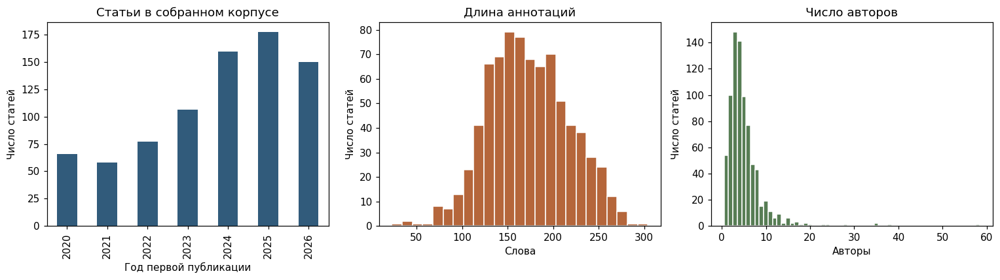

,Поле,Записей,arXiv ID,Названия
0,title,2,"2510.18416, 2606.02638",SegTune: Structured and Fine-Grained Control for Song Generation | SegTune: Struc...
1,abstract,2,"2605.31295, 2606.18790",Latent Space Disentanglement via Activation Steering for Interpretable Attribute ...


,Признак,Нижняя граница,Верхняя граница,Ниже,Выше
0,abstract_words,50.5,294.5,3,1
1,title_words,3.0,19.0,0,6
2,author_count,-1.5,10.5,0,50


,arxiv_id,title,author_count
489,2503.08638,YuE: Scaling Open Foundation Models for Long-Form Music Generation,58
413,2409.09214,Seed-Music: A Unified Framework for High Quality and Controlled Music Generation,38
327,2402.16153,ChatMusician: Understanding and Generating Music Intrinsically with LLM,35


,arxiv_id,title,abstract_words
126,2201.08526,Can Machines Generate Personalized Music? A Hybrid Favorite-aware Method for User...,23
19,2006.09838,LSTM Networks for Music Generation,35
66,2101.00169,Generative Deep Learning for Virtuosic Classical Music: Generative Adversarial Ne...,43


Одинаковые аннотации могут усиливать связь разных ID; IQR-флаги требуют проверки, записи не удаляются.


In [16]:
papers['abstract_words'] = papers.abstract.str.findall(r'\b[A-Za-z]+\b').str.len()
papers['title_words'] = papers.title.str.findall(r'\b[A-Za-z]+\b').str.len()
papers['author_count'] = papers.authors.map(len)
quality = pd.DataFrame({
    'Проверка': ['Число статей', 'Дубли ID', 'Повторные названия без учёта регистра',
                 'Пустые названия', 'Пустые аннотации', 'Пустые списки авторов'],
    'Значение': [len(papers), papers.arxiv_id.duplicated().sum(),
                 papers.title.str.lower().duplicated().sum(),
                 papers.title.str.strip().eq('').sum(), papers.abstract.str.strip().eq('').sum(),
                 papers.authors.map(len).eq(0).sum()]})
display(quality)
display(papers[['abstract_words', 'title_words', 'author_count']].describe().round(1))
display(papers.nlargest(3, 'abstract_words')[['arxiv_id', 'title', 'abstract_words']])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
papers.year.value_counts().sort_index().plot.bar(ax=axes[0], color='#315b7b')
axes[0].set(title='Статьи в собранном корпусе', xlabel='Год первой публикации', ylabel='Число статей')
axes[1].hist(papers.abstract_words, bins=25, color='#b5663b', edgecolor='white')
axes[1].set(title='Длина аннотаций', xlabel='Слова', ylabel='Число статей')
axes[2].hist(papers.author_count, bins=np.arange(0.5, papers.author_count.max()+1.5), color='#577d54', edgecolor='white')
axes[2].set(title='Число авторов', xlabel='Авторы', ylabel='Число статей')
fig.tight_layout(); save_figure('01_eda')

# Одинаковый текст и статистический выброс сами по себе не означают ошибку записи.
duplicate_rows = []
for field in ('title', 'abstract'):
    normalized = papers[field].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
    for _, group in papers[normalized.duplicated(keep=False)].groupby(normalized):
        duplicate_rows.append({'Поле': field, 'Записей': len(group),
                               'arXiv ID': ', '.join(group.arxiv_id),
                               'Названия': ' | '.join(group.title)})
duplicate_audit = pd.DataFrame(duplicate_rows)
display(duplicate_audit)
duplicate_audit.to_csv(RESULTS / 'duplicate_texts.csv', index=False, encoding='utf-8-sig')

outlier_rows, outlier_records = [], []
for field in ('abstract_words', 'title_words', 'author_count'):
    q1, q3 = papers[field].quantile([.25, .75])
    low, high = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
    low_mask, high_mask = papers[field] < low, papers[field] > high
    outlier_rows.append({'Признак': field, 'Нижняя граница': low, 'Верхняя граница': high,
                         'Ниже': int(low_mask.sum()), 'Выше': int(high_mask.sum())})
    for row in papers[low_mask | high_mask].itertuples():
        outlier_records.append({'Признак': field, 'arxiv_id': row.arxiv_id, 'title': row.title,
                                'Значение': getattr(row, field), 'url': row.url})
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
outlier_summary.to_csv(RESULTS / 'outlier_summary.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(outlier_records).to_csv(RESULTS / 'outlier_records.csv', index=False, encoding='utf-8-sig')
display(papers.nlargest(3, 'author_count')[['arxiv_id', 'title', 'author_count']])
display(papers.nsmallest(3, 'abstract_words')[['arxiv_id', 'title', 'abstract_words']])
print('Одинаковые аннотации могут усиливать связь разных ID; IQR-флаги требуют проверки, записи не удаляются.')


,Категория arXiv,Статей
0,cs.SD,704
1,eess.AS,568
2,cs.AI,325
3,cs.LG,266
4,cs.MM,162
5,cs.CL,77
6,cs.HC,53


,Статей с упоминанием,"Доля корпуса, %"
Текстовое условие,181,22.8
Тембр / инструменты,158,19.9
Темп / ритм,155,19.5
Гармония / аккорды,145,18.3
Вокал / слова песни,144,18.2
Длинная форма,100,12.6
Видео,100,12.6
Настроение,89,11.2
Дорожки / источники,71,9.0


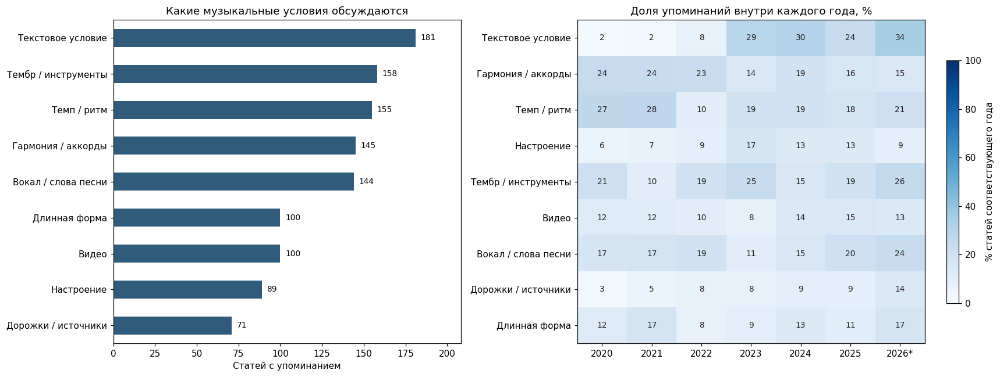

,Работа,Год,Результат,Чем управляют,Что отличает задачу,Источник
0,Jukebox,2020,Аудио с пением,"Исполнитель, жанр, слова песни",Дискретные VQ-VAE-коды и авторегрессия,https://arxiv.org/abs/2005.00341
1,MusicGen,2023,Музыкальное аудио,Текст и мелодия,Авторегрессия по кодам аудиокодека,https://arxiv.org/abs/2306.05284
2,Mustango,2023,Музыкальное аудио,"Текст, аккорды, темп, тональность",Музыкальные условия внутри диффузии,https://arxiv.org/abs/2311.08355
3,MuseCoco,2023,Символьные ноты,Музыкальные атрибуты из текста,Редактируемое нотное представление,https://arxiv.org/abs/2306.00110
4,MusicMagus,2024,Редактирование аудио,Текст о желаемом изменении,Сохранение остальных свойств исходной музыки,https://arxiv.org/abs/2402.06178
5,ShredGP,2023,GuitarPro-табулатура,Стиль гитариста,Техника исполнения и аппликатура в представлении,https://arxiv.org/abs/2307.05324
6,TRIA,2025,Запись барабанов,Аудиоподсказки ритма и тембра,Постукивание или битбокс превращаются в барабаны,https://arxiv.org/abs/2509.15625
7,GuideSep,2025,Источник из готового микса,Напетая мелодия и маска спектрограммы,"Разделение существующей записи, отдельная задача",https://arxiv.org/abs/2507.01339
8,Diff-BGM,2024,Музыкальное аудио,Движение и смысл видеоряда,Ритм и атмосфера согласуются с видео,https://arxiv.org/abs/2405.11913
9,Diff-Symbo,2026,Длинная символьная музыка,Текст,Авторегрессивное продолжение латентной диффузии,https://arxiv.org/abs/2608.05222


В [MusicRLVR](https://arxiv.org/abs/2609.23665) авторы сообщают: Llama-3.1-70B выполняет 63,0% заданий с одним музыкальным ограничением и 4,4% с четырьмя. Это опубликованный результат их бенчмарка. В [MIRA](https://arxiv.org/abs/2610.10355) предлагается проверять требования по отдельности: общий балл сходства текста и звука может скрыть неверный инструмент или несоблюдение ритма. Модели этих работ в ноутбуке не запускаются.

In [17]:
category_counts = Counter(category for categories in papers.categories for category in categories)
display(pd.DataFrame(category_counts.most_common(7), columns=['Категория arXiv', 'Статей']))

# Неисключающие признаки названия и аннотации, а не экспертная классификация моделей.
task_rules = {
    'Текстовое условие': r'text.to.music|text.condition|textual|natural.language|text.description|text.prompt',
    'Гармония / аккорды': r'\bchord\w*|\bharmon\w*|\btonal\w*|key signature',
    'Темп / ритм': r'\btempo\b|\bbpm\b|\brhythm\w*|\bbeat\w*',
    'Настроение': r'\bemotion\w*|\bmood\w*|\baffective\b',
    'Тембр / инструменты': r'\btimbr\w*|\binstrument\w*|\borchestrat\w*',
    'Видео': r'\bvideo\w*|\bvisual\b|\bfilm\b',
    'Вокал / слова песни': r'\bsinging\b|\bvocal\w*|\blyric\w*',
    'Дорожки / источники': r'\bstems?\b|source separation|multi.track|multitrack',
    'Длинная форма': r'long.form|long.term|long.duration|long.context|long.range|full.song|musical structure|music structure',
}
task_text = (papers.title + ' ' + papers.abstract).str.lower()
task_mentions = pd.DataFrame({name: task_text.str.contains(pattern, regex=True)
                              for name, pattern in task_rules.items()}, index=papers.index)
task_counts = task_mentions.sum().sort_values(ascending=False)
task_table = pd.DataFrame({'Статей с упоминанием': task_counts,
                           'Доля корпуса, %': (100 * task_counts / len(papers)).round(1)})
display(task_table)
task_table.to_csv(RESULTS / 'task_mentions.csv', encoding='utf-8-sig')
task_mentions.assign(arxiv_id=papers.arxiv_id).to_csv(RESULTS / 'article_task_mentions.csv', index=False, encoding='utf-8-sig')
by_year = task_mentions.groupby(papers.year).mean().T * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.25]})
task_counts.sort_values().plot.barh(ax=axes[0], color='#315b7b')
axes[0].set(xlabel='Статей с упоминанием', ylabel='', title='Какие музыкальные условия обсуждаются')
for bar in axes[0].patches:
    axes[0].text(bar.get_width()+3, bar.get_y()+bar.get_height()/2, str(int(bar.get_width())), va='center', fontsize=9)
axes[0].set_xlim(0, task_counts.max()*1.15)
image = axes[1].imshow(by_year, cmap='Blues', vmin=0, vmax=100, aspect='auto')
axes[1].set(xticks=range(len(by_year.columns)), xticklabels=[str(year)+('*' if year==2026 else '') for year in by_year.columns],
            yticks=range(len(by_year)), yticklabels=by_year.index, title='Доля упоминаний внутри каждого года, %')
for i in range(len(by_year)):
    for j in range(len(by_year.columns)):
        value = by_year.iloc[i, j]
        axes[1].text(j, i, f'{value:.0f}', ha='center', va='center', fontsize=9,
                     color='white' if value > 50 else '#202020')
fig.colorbar(image, ax=axes[1], shrink=.75, label='% статей соответствующего года')
fig.tight_layout(); save_figure('02a_musical_controls')

case_specs = [
 ('2005.00341', 'Jukebox', 'Аудио с пением', 'Исполнитель, жанр, слова песни', 'Дискретные VQ-VAE-коды и авторегрессия'),
 ('2306.05284', 'MusicGen', 'Музыкальное аудио', 'Текст и мелодия', 'Авторегрессия по кодам аудиокодека'),
 ('2311.08355', 'Mustango', 'Музыкальное аудио', 'Текст, аккорды, темп, тональность', 'Музыкальные условия внутри диффузии'),
 ('2306.00110', 'MuseCoco', 'Символьные ноты', 'Музыкальные атрибуты из текста', 'Редактируемое нотное представление'),
 ('2402.06178', 'MusicMagus', 'Редактирование аудио', 'Текст о желаемом изменении', 'Сохранение остальных свойств исходной музыки'),
 ('2307.05324', 'ShredGP', 'GuitarPro-табулатура', 'Стиль гитариста', 'Техника исполнения и аппликатура в представлении'),
 ('2509.15625', 'TRIA', 'Запись барабанов', 'Аудиоподсказки ритма и тембра', 'Постукивание или битбокс превращаются в барабаны'),
 ('2507.01339', 'GuideSep', 'Источник из готового микса', 'Напетая мелодия и маска спектрограммы', 'Разделение существующей записи, отдельная задача'),
 ('2405.11913', 'Diff-BGM', 'Музыкальное аудио', 'Движение и смысл видеоряда', 'Ритм и атмосфера согласуются с видео'),
 ('2608.05222', 'Diff-Symbo', 'Длинная символьная музыка', 'Текст', 'Авторегрессивное продолжение латентной диффузии'),
 ('2503.08638', 'YuE', 'Вокал и аккомпанемент', 'Слова песни', 'Связность полного исполнения песни'),
 ('2610.10355', 'MIRA', 'Уточнение запросов к генератору', 'Критерии конкретного музыкального замысла', 'Проверка отдельных требований и поиск правок запроса'),
]
case_table = pd.DataFrame([
 {'Работа': name, 'Год': int(papers.set_index('arxiv_id').loc[aid, 'year']),
  'Результат': output, 'Чем управляют': control, 'Что отличает задачу': difference,
  'Источник': f'https://arxiv.org/abs/{aid}'}
 for aid, name, output, control, difference in case_specs])
assert {aid for aid, *_ in case_specs} <= set(papers.arxiv_id)
display(case_table)
case_table.to_csv(RESULTS / 'musical_cases.csv', index=False, encoding='utf-8-sig')
display(Markdown(
    'В [MusicRLVR](https://arxiv.org/abs/2609.23665) авторы сообщают: Llama-3.1-70B '
    'выполняет 63,0% заданий с одним музыкальным ограничением и 4,4% с четырьмя. '
    'Это опубликованный результат их бенчмарка. В [MIRA](https://arxiv.org/abs/2610.10355) '
    'предлагается проверять требования по отдельности: общий балл сходства текста и звука может скрыть '
    'неверный инструмент или несоблюдение ритма. Модели этих работ в ноутбуке не запускаются.'))


## 2 Текст и ключевые слова

Известная ошибка отбора: [2606.31158](https://arxiv.org/abs/2606.31158) генерирует действия робота по музыке, а не музыку.

Нормализация: удаление URL и формул, нижний регистр, разделение по дефисам, WordNet для глаголов и существительных, отдельная обработка сокращений.

Для Ципфа получено 140 946 слов и 5 707 лемм. На рангах 10–1000 с частотой ≥2: $\alpha=1{,}002$, $R^2=0{,}988$. Начало и хвост распределения отклоняются от прямой.

Для Хипса: $V=Kn^\beta$, $\beta=0{,}520$ на медианной кривой 20 перестановок статей. Диапазон аппроксимации: 1 000–140 946 токенов.


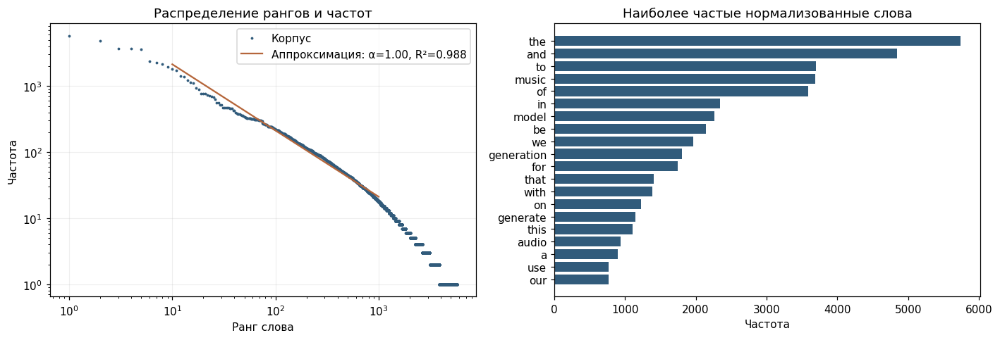

Токенов: 140,946; словарь: 5,707; α=1.0021; R²=0.9884


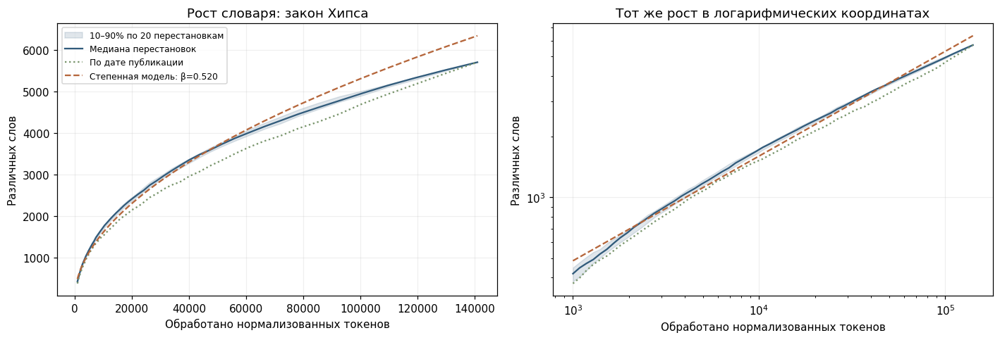

,tokens,vocabulary,beta_median_curve,r2,beta_min,beta_max,permutations,fit_min_tokens
0,140946,5707,0.5196,0.9935,0.506,0.5388,20,1000


β описывает этот корпус и диапазон; за пределами наблюдений рост словаря не проверялся.


In [18]:
texts = (papers.title + '. ' + papers.abstract).tolist()
token_lists = [normalized_words(text) for text in texts]
frequency = Counter(word for words in token_lists for word in words)
ranked = frequency.most_common()
ranks = np.arange(1, len(ranked)+1)
counts = np.array([count for word, count in ranked])
fit_mask = (ranks >= 10) & (ranks <= 1000) & (counts >= 2)
fit = linregress(np.log10(ranks[fit_mask]), np.log10(counts[fit_mask]))
alpha, r_squared = -fit.slope, fit.rvalue**2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(ranks, counts, '.', markersize=3, color='#315b7b', label='Корпус')
axes[0].loglog(ranks[fit_mask], 10**fit.intercept * ranks[fit_mask]**fit.slope,
               color='#b5663b', label=f'Аппроксимация: α={alpha:.2f}, R²={r_squared:.3f}')
axes[0].set(xlabel='Ранг слова', ylabel='Частота', title='Распределение рангов и частот')
axes[0].legend(); axes[0].grid(alpha=0.2)
top = frequency.most_common(20)
axes[1].barh([word for word, count in top][::-1], [count for word, count in top][::-1], color='#315b7b')
axes[1].set(xlabel='Частота', title='Наиболее частые нормализованные слова')
fig.tight_layout(); save_figure('02_zipf')
print(f'Токенов: {sum(counts):,}; словарь: {len(frequency):,}; α={alpha:.4f}; R²={r_squared:.4f}')

# Рост словаря; разброс показывает влияние порядка документов, а не доверительный интервал.
heaps_total = sum(map(len, token_lists))
heaps_steps = np.unique(np.geomspace(1000, heaps_total, 60).astype(int))
heaps_steps[-1] = heaps_total

def vocabulary_growth(order):
    tokens = [word for index in order for word in token_lists[index]]
    seen, values, previous = set(), [], 0
    for stop in heaps_steps:
        seen.update(tokens[previous:stop])
        values.append(len(seen))
        previous = stop
    return np.array(values)

heaps_chronological = vocabulary_growth(np.arange(len(token_lists)))
heaps_rng = np.random.default_rng(SEED)
heaps_curves = np.array([vocabulary_growth(heaps_rng.permutation(len(token_lists))) for _ in range(20)])
heaps_median = np.median(heaps_curves, axis=0)
heaps_low, heaps_high = np.percentile(heaps_curves, [10, 90], axis=0)
heaps_fit = linregress(np.log10(heaps_steps), np.log10(heaps_median))
heaps_betas = [linregress(np.log10(heaps_steps), np.log10(curve)).slope for curve in heaps_curves]
assert np.all(np.diff(heaps_curves, axis=1) >= 0)
assert np.all(heaps_curves[:, -1] == len(frequency))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax in axes:
    ax.fill_between(heaps_steps, heaps_low, heaps_high, color='#315b7b', alpha=.15,
                    label='10–90% по 20 перестановкам')
    ax.plot(heaps_steps, heaps_median, color='#315b7b', label='Медиана перестановок')
    ax.plot(heaps_steps, heaps_chronological, color='#78946b', linestyle=':', label='По дате публикации')
    ax.plot(heaps_steps, 10**heaps_fit.intercept * heaps_steps**heaps_fit.slope,
            '--', color='#b5663b', label=f'Степенная модель: β={heaps_fit.slope:.3f}')
    ax.set(xlabel='Обработано нормализованных токенов', ylabel='Различных слов')
    ax.grid(alpha=.2)
axes[0].set_title('Рост словаря: закон Хипса')
axes[1].set(xscale='log', yscale='log', title='Тот же рост в логарифмических координатах')
axes[0].legend(fontsize=8)
fig.tight_layout(); save_figure('02_heaps')
heaps_result = {'tokens': heaps_total, 'vocabulary': len(frequency),
                'beta_median_curve': float(heaps_fit.slope), 'r2': float(heaps_fit.rvalue**2),
                'beta_min': float(min(heaps_betas)), 'beta_max': float(max(heaps_betas)),
                'permutations': 20, 'fit_min_tokens': int(heaps_steps[0])}
(RESULTS / 'heaps.json').write_text(json.dumps(heaps_result, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([heaps_result]).round(4))
print('β описывает этот корпус и диапазон; за пределами наблюдений рост словаря не проверялся.')


In [19]:
vectorizer, matrix, keyword_sets, keyword_scores = extract_keywords(papers, top_n=10, min_df=3, max_df=0.7)
papers['keywords'] = keyword_sets
papers['keyword_count'] = papers.keywords.map(len)
keywords_by_id = dict(zip(papers.arxiv_id, keyword_sets))
assert papers.keyword_count.gt(0).all(), 'Статья без тегов: проверить параметры'
display(papers[['arxiv_id', 'title', 'keywords']].head(6))
print('Кандидатов в словаре:', matrix.shape[1], 'медиана тегов на статью:', papers.keyword_count.median())
tag_rows = [{'arxiv_id': paper_id, 'keyword': term, 'tfidf': score, 'ngram': len(term.split())}
            for paper_id, terms, scores in zip(papers.arxiv_id, keyword_sets, keyword_scores)
            for term, score in zip(terms, scores)]
tag_table = pd.DataFrame(tag_rows)
tag_table.to_csv(RESULTS / 'keywords.csv', index=False, encoding='utf-8-sig')
display(tag_table.ngram.value_counts().sort_index().rename_axis('Длина n-граммы').to_frame('Выбранных тегов'))
print('Словарь и теги получены автоматически; таблица позволяет проверить качество выделения.')
# Частота в исходных текстах и частота выбора в top-10 различаются.
selected_df = Counter(term for terms in keyword_sets for term in terms)
singleton_count = sum(count == 1 for count in selected_df.values())
display(pd.DataFrame({'Показатель': ['Терминов в выбранных тегах', 'Выбраны только для одной статьи',
                                   'Доля однократно выбранных, %'],
                      'Значение': [len(selected_df), singleton_count, 100*singleton_count/len(selected_df)]}))
tag_audit = pd.DataFrame([{'Тег': term, 'Статей, где выбран': count,
                           'Статей с фразой в тексте': int((matrix[:, vectorizer.vocabulary_[term]] > 0).sum())}
                          for term, count in selected_df.items()])
tag_audit.to_csv(RESULTS / 'tag_selection_audit.csv', index=False, encoding='utf-8-sig')
display(tag_audit[tag_audit['Тег'].isin(['simple', 'better control', 'automatic and human', 'musicgen'])])


,arxiv_id,title,keywords
0,2001.00576,DAWSON: A Domain Adaptive Few Shot Generation Framework,"[meta, train procedure, gan, shoot generation, adaptive, learn algorithm, domain,..."
1,2002.00212,Pop Music Transformer: Beat-based Modeling and Generation of Expressive Pop Piano...,"[pop piano, pop music, music transformer, impose, base model, beat, expressive, t..."
2,2002.02393,Continuous Melody Generation via Disentangled Short-Term Representations and Stru...,"[rhythm pattern, short term, disentangle, note sequence, melody generation, struc..."
3,2002.03854,Attentional networks for music generation,"[bi lstm, network for music, success, attention, lack structure, old, lstm neural..."
4,2002.03082,RL-Duet: Online Music Accompaniment Generation Using Deep Reinforcement Learning,"[reinforcement, music accompaniment, online, rl, algorithm, generation use deep, ..."
5,2002.10266,"Rhythm, Chord and Melody Generation for Lead Sheets using Recurrent Neural Networks","[lead sheet, recurrent neural, template, melody generation, neural network, sheet..."


Кандидатов в словаре: 5319 медиана тегов на статью: 10.0


,Выбранных тегов
Длина n-граммы,
1,4546
2,2522
3,862


Словарь и теги получены автоматически; таблица позволяет проверить качество выделения.


,Показатель,Значение
0,Терминов в выбранных тегах,3360.000000
1,Выбраны только для одной статьи,1489.000000
2,"Доля однократно выбранных, %",44.315476


,Тег,"Статей, где выбран",Статей с фразой в тексте
431,automatic and human,3,3
647,simple,5,46
1210,better control,2,3
1563,musicgen,7,30


## 3 Граф ключевых слов

Узел: тег. Вес ребра: число статей, для которых оба тега выбраны вместе, $w_{ij}=\sum_d[i,j\in K_d]$.

Louvain: `resolution=1`, `seed=42`. Сравнение с другими seed, greedy modularity и случайным распределением терминов между группами тех же размеров.

Расчёты используют полный граф. На рисунке слева 90 тегов с наибольшей суммой весов; цвет обозначает группу, размер узла зависит от частоты выбора. Справа суммарные веса межгрупповых связей, логарифмическая шкала, диагональ обнулена.


In [20]:
G = keyword_graph(keyword_sets)
communities = nx.community.louvain_communities(G, weight='weight', resolution=1, seed=SEED)
communities = sorted(communities, key=lambda nodes: (-len(nodes), min(nodes)))
community_id = {term: group for group, terms in enumerate(communities) for term in terms}
nx.set_node_attributes(G, community_id, 'community')
modularity = nx.community.modularity(G, communities, weight='weight')
components = sorted(nx.connected_components(G), key=len, reverse=True)
display(pd.DataFrame([{
    'Узлы': G.number_of_nodes(), 'Рёбра': G.number_of_edges(), 'Плотность': nx.density(G),
    'Компоненты': len(components), 'Изолированные узлы': nx.number_of_isolates(G),
    'Средняя кластеризация без весов': nx.average_clustering(G),
    'Сообщества Louvain': len(communities), 'Модулярность': modularity}]).round(4))
comparisons = []
for seed in (7, 42, 123):
    partition = nx.community.louvain_communities(G, weight='weight', seed=seed)
    comparisons.append({'Алгоритм': 'Louvain', 'seed': seed, 'Кластеры': len(partition),
                        'Q': nx.community.modularity(G, partition, weight='weight')})
greedy = list(nx.community.greedy_modularity_communities(G, weight='weight'))
comparisons.append({'Алгоритм': 'Greedy modularity', 'seed': None, 'Кластеры': len(greedy),
                    'Q': nx.community.modularity(G, greedy, weight='weight')})
display(pd.DataFrame(comparisons).round(4))
rng = np.random.default_rng(SEED)
nodes = list(G)
sizes = [len(group) for group in communities]
random_q = []
for repeat in range(20):
    permuted = rng.permutation(nodes)
    boundaries = np.cumsum([0] + sizes)
    partition = [set(permuted[boundaries[i]:boundaries[i+1]]) for i in range(len(sizes))]
    random_q.append(nx.community.modularity(G, partition, weight='weight'))
print(f'Louvain Q={modularity:.4f}; случайные метки: среднее Q={np.mean(random_q):.4f}, std={np.std(random_q):.4f}')
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
partitions = {seed: nx.community.louvain_communities(G, weight='weight', seed=seed)
              for seed in (7, 42, 123)}
partition_labels = {seed: {term: group for group, terms in enumerate(partition) for term in terms}
                    for seed, partition in partitions.items()}
stability_rows = []
for a, b in combinations(partitions, 2):
    labels_a = [partition_labels[a][term] for term in G]
    labels_b = [partition_labels[b][term] for term in G]
    stability_rows.append({'seed A': a, 'seed B': b,
                           'ARI': adjusted_rand_score(labels_a, labels_b),
                           'NMI': normalized_mutual_info_score(labels_a, labels_b)})
cluster_stability = pd.DataFrame(stability_rows)
display(cluster_stability.round(4))
cluster_stability.to_csv(RESULTS / 'cluster_stability.csv', index=False, encoding='utf-8-sig')


,Узлы,Рёбра,Плотность,Компоненты,Изолированные узлы,Средняя кластеризация без весов,Сообщества Louvain,Модулярность
0,3360,34628,0.0061,1,0,0.6528,24,0.4223


,Алгоритм,seed,Кластеры,Q
0,Louvain,7.0,21,0.4215
1,Louvain,42.0,24,0.4223
2,Louvain,123.0,22,0.4247
3,Greedy modularity,NaN,11,0.3892


Louvain Q=0.4223; случайные метки: среднее Q=-0.0008, std=0.0009


,seed A,seed B,ARI,NMI
0,7,42,0.2188,0.3828
1,7,123,0.2698,0.4217
2,42,123,0.2526,0.4155


In [21]:
strength = dict(G.degree(weight='weight'))
community_names = ['Мелодия, ритм и гармоническая структура', 'Синтез пения и голос', 'Эмоции, MIDI, жанры и смещения', 'Диффузия, VAE и музыкальные представления', 'Языковые модели, мультимодальность и агенты', 'Видео и ритмическое согласование', 'GAN, внимание и генеративные архитектуры', 'Текстовая генерация, оценка и атрибуция', 'Детекция синтетической музыки и длинные последовательности', 'Живой аккомпанемент и потоковая генерация', 'Мультимодальные представления и интерпретируемость', 'Символьная генерация и явные ограничения', 'Гитара, табулатуры и обзорные методы', 'Выразительное пианино и Transformer', 'Полные песни и управление генерацией', 'LSTM и взаимодействие с человеком', 'Отдельные источники и дорожки', 'Кодирование мелодии и гармонии', 'Управление диффузией и уточнение результата', 'Редактирование, петли и музыкальные атрибуты', 'Disentanglement и управляемые представления', 'Структура партитуры и композиция', 'MusicGen, культура и прикладные сценарии', 'Автоэнкодеры и вспомогательные признаки']
assert len(community_names) == len(communities)
cluster_rows = []
for group, terms in enumerate(communities):
    top_terms = sorted(terms, key=lambda term: (-strength[term], term))[:5]
    cluster_rows.append({'Группа': group, 'Рабочее название': community_names[group],
                        'Терминов': len(terms), 'Опорные теги': ', '.join(top_terms),
                        'Статей с ≥3 тегами': int(papers.keywords.map(lambda tags: len(set(tags) & terms) >= 3).sum())})
cluster_table = pd.DataFrame(cluster_rows)
display(cluster_table)
cluster_table.to_csv(RESULTS / 'communities.csv', index=False, encoding='utf-8-sig')
# Для каждой группы основного запуска ищем наиболее похожую группу другого seed.
group_stability = []
for group, terms in enumerate(communities):
    matches = [max(len(terms & other)/len(terms | other) for other in partitions[seed]) for seed in (7, 123)]
    group_stability.append({'Группа': group, 'Название': community_names[group],
                            'Лучший Jaccard, seed 7': matches[0], 'Лучший Jaccard, seed 123': matches[1],
                            'Минимум по двум запускам': min(matches)})
group_stability = pd.DataFrame(group_stability).sort_values('Минимум по двум запускам', ascending=False)
display(group_stability.head(6).round(3))
group_stability.to_csv(RESULTS / 'community_stability.csv', index=False, encoding='utf-8-sig')


,Группа,Рабочее название,Терминов,Опорные теги,Статей с ≥3 тегами
0,0,"Мелодия, ритм и гармоническая структура",272,"melody generation, rhythm, hierarchical, generate melody, harmony",69
1,1,Синтез пения и голос,255,"sing, svs, aware, voice, timbre",73
2,2,"Эмоции, MIDI, жанры и смещения",228,"emotion, midi, genre, emotional, semantic",50
3,3,"Диффузия, VAE и музыкальные представления",218,"diffusion model, symbolic music, latent diffusion, token, bar",54
4,4,"Языковые модели, мультимодальность и агенты",190,"llm, composer, language model, audio generation, agent",54
5,5,Видео и ритмическое согласование,190,"video, beat, visual, caption, multimodal",54
6,6,"GAN, внимание и генеративные архитектуры",189,"gan, generative adversarial, adversarial network, chord, attention",40
7,7,"Текстовая генерация, оценка и атрибуция",167,"text to music, generative music, music generation model, reward, attribution",36
8,8,Детекция синтетической музыки и длинные последовательности,152,"ai generate music, lyric, detection, long term, segment",33
9,9,Живой аккомпанемент и потоковая генерация,149,"real time, accompaniment generation, discrete, live, mix",40


,Группа,Название,"Лучший Jaccard, seed 7","Лучший Jaccard, seed 123",Минимум по двум запускам
1,1,Синтез пения и голос,0.594,0.665,0.594
5,5,Видео и ритмическое согласование,0.414,0.536,0.414
20,20,Disentanglement и управляемые представления,0.306,0.462,0.306
12,12,"Гитара, табулатуры и обзорные методы",0.291,0.485,0.291
9,9,Живой аккомпанемент и потоковая генерация,0.286,0.292,0.286
4,4,"Языковые модели, мультимодальность и агенты",0.282,0.315,0.282


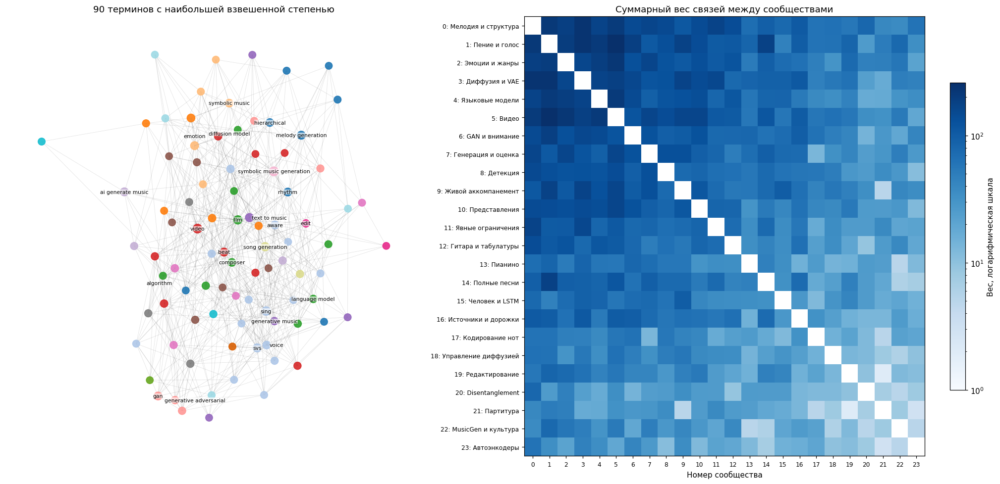

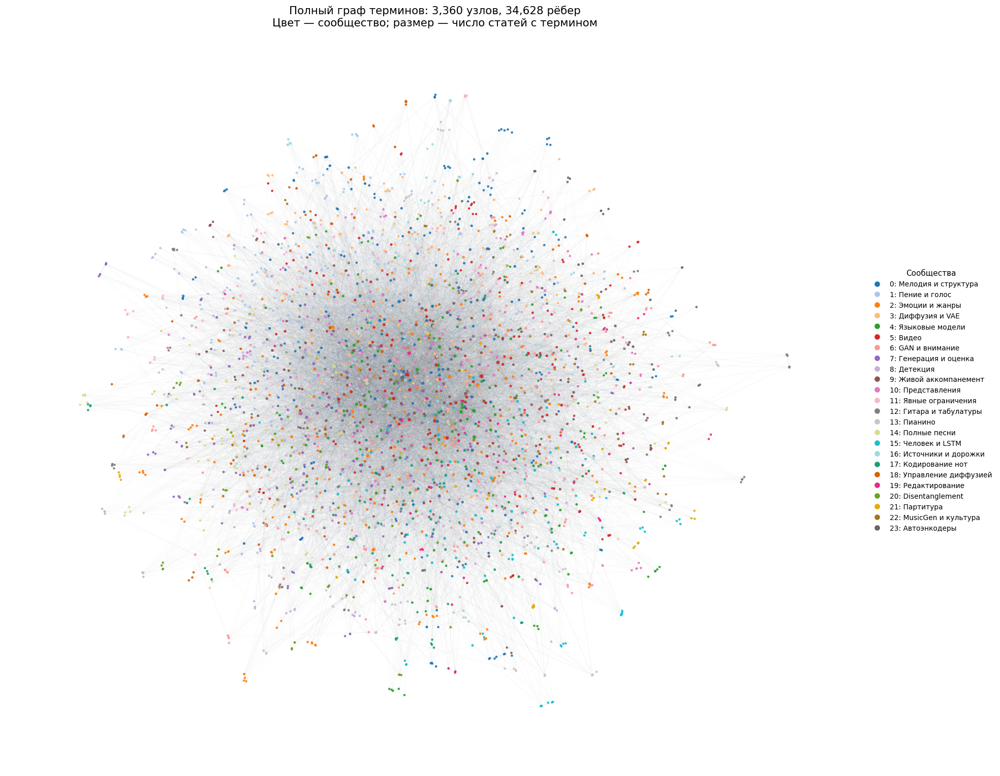

In [22]:
core_nodes = sorted(G, key=lambda node: (-strength[node], node))[:90]
core = G.subgraph(core_nodes)
pos = nx.spring_layout(core, seed=SEED, weight='weight', iterations=100)
fig, axes = plt.subplots(1, 2, figsize=(19, 9), gridspec_kw={'width_ratios': [1, 1.2]})
colors = [community_id[node] for node in core]
from matplotlib.colors import ListedColormap
community_palette = ListedColormap(list(plt.cm.tab20.colors) + list(plt.cm.Dark2.colors))
nx.draw_networkx_edges(core, pos, ax=axes[0], alpha=0.12, width=0.5)
nx.draw_networkx_nodes(core, pos, ax=axes[0], node_color=colors, cmap=community_palette, vmin=0, vmax=len(communities)-1,
                       node_size=[60 + 3 * G.nodes[node]['document_frequency'] for node in core], alpha=0.9)
labels = {node: node for node in core_nodes[:24]}
label_pos = {node: point.copy() for node, point in pos.items()}
for term, offset in {'music generation model': (0, 0.07), 'algorithm': (-0.08, -0.05), 'diffusion model': (0.18, 0.04), 'caption': (-0.06, -0.06), 'emotion': (0.07, -0.06)}.items():
    if term in label_pos:
        label_pos[term] = label_pos[term] + np.array(offset)
label_texts = nx.draw_networkx_labels(core, label_pos, labels, ax=axes[0], font_size=7,
                        bbox={'facecolor': 'white', 'alpha': 0.65, 'edgecolor': 'none', 'pad': 0.1})
axes[0].set_title('90 терминов с наибольшей взвешенной степенью'); axes[0].axis('off')
cluster_graph = nx.Graph()
for group, terms in enumerate(communities):
    cluster_graph.add_node(group, size=len(terms))
for left, right, attrs in G.edges(data=True):
    a, b = community_id[left], community_id[right]
    if a != b:
        old = cluster_graph.get_edge_data(a, b, {}).get('weight', 0)
        cluster_graph.add_edge(a, b, weight=old + attrs['weight'])
short_names = ['Мелодия и структура', 'Пение и голос', 'Эмоции и жанры', 'Диффузия и VAE',
               'Языковые модели', 'Видео', 'GAN и внимание', 'Генерация и оценка',
               'Детекция', 'Живой аккомпанемент', 'Представления', 'Явные ограничения',
               'Гитара и табулатуры', 'Пианино', 'Полные песни', 'Человек и LSTM',
               'Источники и дорожки', 'Кодирование нот', 'Управление диффузией',
               'Редактирование', 'Disentanglement', 'Партитура', 'MusicGen и культура', 'Автоэнкодеры']
intergroup = nx.to_numpy_array(cluster_graph, nodelist=range(len(communities)), weight='weight')
from matplotlib.colors import LogNorm
heat = axes[1].imshow(np.ma.masked_equal(intergroup, 0), cmap='Blues',
                      norm=LogNorm(vmin=1, vmax=intergroup.max()), aspect='auto')
axes[1].set(xticks=range(len(communities)), yticks=range(len(communities)),
            xticklabels=range(len(communities)),
            yticklabels=[f'{i}: {name}' for i, name in enumerate(short_names)],
            xlabel='Номер сообщества', title='Суммарный вес связей между сообществами')
axes[1].tick_params(labelsize=8)
fig.colorbar(heat, ax=axes[1], shrink=.7, label='Вес, логарифмическая шкала')
fig.tight_layout()
# Подписи разводятся в координатах рисунка; линии указывают соответствующие узлы.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
placed_boxes = []
for term, label in label_texts.items():
    anchor = axes[0].transData.transform(label.get_position())
    found = False
    for dy in (0, 14, -14, 28, -28, 42, -42, 56, -56):
        for dx in (0, 20, -20, 40, -40, 60, -60):
            label.set_position(axes[0].transData.inverted().transform(anchor + [dx, dy]))
            box = label.get_window_extent(renderer).expanded(1.04, 1.3)
            if not any(box.overlaps(other) for other in placed_boxes):
                placed_boxes.append(box)
                found = True
                break
        if found:
            break
    location = label.get_position()
    axes[0].plot([pos[term][0], location[0]], [pos[term][1], location[1]], color='#999999', linewidth=0.4, alpha=0.5)
save_figure('03_keyword_graph')
nx.write_graphml(G, RESULTS / 'keyword_graph.graphml')

full_term_pos = nx.spring_layout(G, seed=SEED, weight='weight', iterations=65, method='force')
fig, ax = plt.subplots(figsize=(18, 14))
nx.draw_networkx_edges(G, full_term_pos, ax=ax, alpha=0.045, width=0.25, edge_color='#52606d')
nx.draw_networkx_nodes(
    G, full_term_pos, ax=ax,
    node_color=[community_id[node] for node in G], cmap=community_palette,
    vmin=0, vmax=len(communities)-1,
    node_size=[5 + 4 * np.sqrt(G.nodes[node]['document_frequency']) for node in G],
    linewidths=0, alpha=0.9,
)
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker='o', linestyle='', markersize=6,
                  color=community_palette(i / (len(communities)-1)), label=f'{i}: {name}')
           for i, name in enumerate(short_names)]
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1, 0.5),
          frameon=False, fontsize=9, title='Сообщества')
ax.set_title(f'Полный граф терминов: {G.number_of_nodes():,} узлов, {G.number_of_edges():,} рёбер'
             '\nЦвет — сообщество; размер — число статей с термином', fontsize=14)
ax.axis('off')
fig.tight_layout()
save_figure('03_full_keyword_graph')


## 4 Сообщества и центральности

Louvain: 24 сообщества, $Q=0{,}4223$. При seed 7 и 123: 21 и 22 группы с близкими Q, но ARI=0,219–0,270. Границы групп нестабильны. Greedy modularity даёт 11 групп и $Q=0{,}3892$.

| Группа | Интерпретация |
|---|---|
| 1 | `sing`, `svs`, `voice`: синтез пения |
| 3 | `symbolic music`, `diffusion model`, `vae`: смешение представлений и архитектур |
| 5 | `video`, `beat`, `synchronization`: музыка по видео и ритмическое согласование |
| 11 | `symbolic music generation`, `rule`, `guidance`: управление символьной генерацией |

Устойчивого разделения аудио и нот нет. Названия относятся к одному разбиению; статья может содержать теги нескольких групп.

Центральности: degree, betweenness, closeness и eigenvector. Для путей длина ребра $1/w$, eigenvector использует исходный вес на крупнейшей компоненте. Betweenness оценивается по 512 источникам; проверка на 256 даёт Spearman=0,9804 и девять совпадений в top-10.


,Проверка приближения betweenness,Значение
0,Корреляция рангов Spearman,0.9804
1,Общих терминов в top-10,9.0000


degree


,degree,document_frequency,community
keyword,,,
symbolic music generation,0.06966,28,11
video,0.06252,27,5
llm,0.05240,22,4
text to music,0.05121,20,7
song generation,0.05031,22,14
sing,0.04942,25,1
beat,0.04882,19,5
diffusion model,0.04644,19,3
aware,0.04644,18,1


betweenness (оценка по 512 источникам)


,betweenness,document_frequency,community
keyword,,,
video,0.08033,27,5
sing,0.06069,25,1
symbolic music generation,0.05243,28,11
llm,0.05006,22,4
symbolic music,0.03865,16,3
diffusion model,0.03346,19,3
emotion,0.03238,17,2
song generation,0.03174,22,14
melody generation,0.02920,19,0


closeness


,closeness,document_frequency,community
keyword,,,
video,0.53853,27,5
sing,0.53659,25,1
voice,0.52330,16,1
beat,0.51910,19,5
svs,0.51904,20,1
voice synthesis,0.51593,12,1
llm,0.51514,22,4
symbolic music generation,0.51402,28,11
lyric,0.50821,14,8


eigenvector


,eigenvector,document_frequency,community
keyword,,,
sing,0.29410,25,1
svs,0.23293,20,1
voice,0.20550,16,1
voice synthesis,0.16918,12,1
video,0.12210,27,5
beat,0.10622,19,5
end,0.10529,11,1
singer,0.10313,7,1
song generation,0.10204,22,14


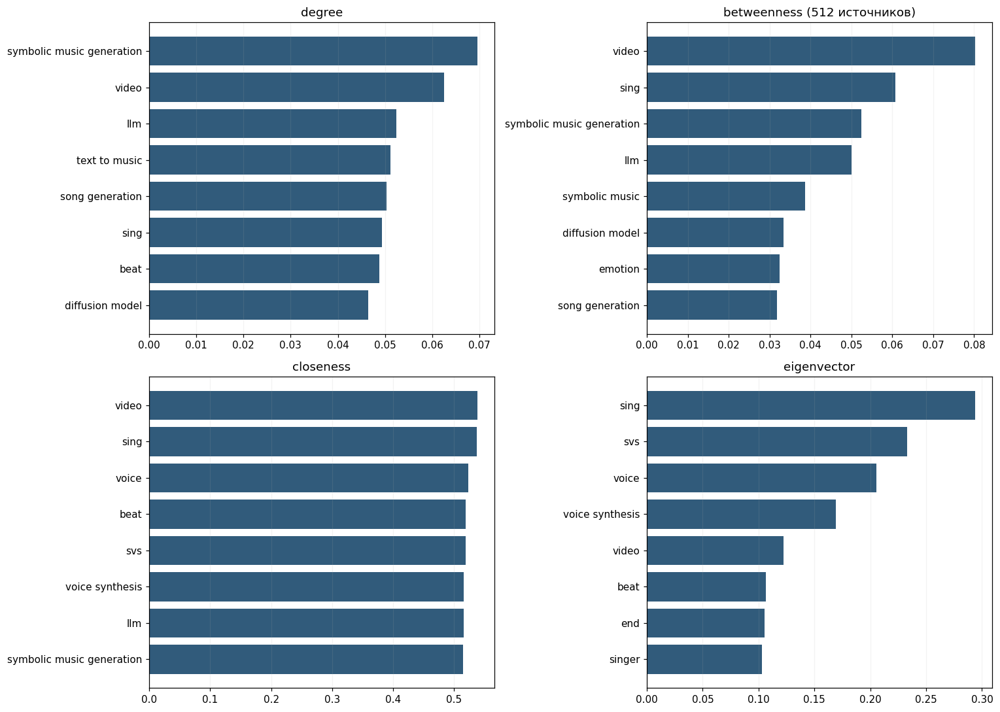

Strength = 9 × частота выбора тега; Spearman(degree, частота) = 0.9942


In [23]:
from scipy.sparse.csgraph import dijkstra
largest = G.subgraph(components[0]).copy()
node_order = list(G)
adjacency = nx.to_scipy_sparse_array(G, nodelist=node_order, weight='distance', format='csr')
distances = dijkstra(adjacency, directed=False)
finite = np.isfinite(distances)
reachable = finite.sum(axis=1) - 1
distance_sum = np.where(finite, distances, 0).sum(axis=1)
closeness_values = np.divide(reachable, distance_sum, out=np.zeros(len(G)), where=distance_sum > 0)
closeness_values *= reachable / (len(G) - 1)
closeness = dict(zip(node_order, closeness_values))
check_nodes = sorted(G, key=lambda term: (-G.degree(term), term))[:6]
for term in check_nodes:
    assert np.isclose(closeness[term], nx.closeness_centrality(G, u=term, distance='distance'), rtol=1e-9)
del distances, finite, adjacency

betweenness = nx.betweenness_centrality(G, k=min(512, len(G)), seed=42, weight='distance', normalized=True)
betweenness_check = nx.betweenness_centrality(G, k=min(256, len(G)), seed=7, weight='distance', normalized=True)
bc_comparison = pd.DataFrame({'512 источников, seed 42': betweenness, '256 источников, seed 7': betweenness_check})
bc_spearman = bc_comparison.corr(method='spearman').iloc[0, 1]
bc_top_overlap = len(set(bc_comparison.nlargest(10, bc_comparison.columns[0]).index)
                     & set(bc_comparison.nlargest(10, bc_comparison.columns[1]).index))
display(pd.DataFrame({'Проверка приближения betweenness': ['Корреляция рангов Spearman', 'Общих терминов в top-10'],
                      'Значение': [round(bc_spearman, 4), bc_top_overlap]}))
centrality = pd.DataFrame({
    'degree': nx.degree_centrality(G), 'strength': dict(G.degree(weight='weight')),
    'betweenness': betweenness, 'closeness': closeness,
    'eigenvector': nx.eigenvector_centrality(largest, weight='weight', max_iter=2000, tol=1e-8)})
centrality.index.name = 'keyword'
centrality['community'] = pd.Series(community_id)
centrality['document_frequency'] = pd.Series(nx.get_node_attributes(G, 'document_frequency'))
centrality.to_csv(RESULTS / 'centralities.csv', encoding='utf-8-sig')
for measure in ('degree', 'betweenness', 'closeness', 'eigenvector'):
    print(measure + (' (оценка по 512 источникам)' if measure=='betweenness' else ''))
    display(centrality.nlargest(10, measure)[[measure, 'document_frequency', 'community']].round(5))
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, measure in zip(axes.ravel(), ('degree', 'betweenness', 'closeness', 'eigenvector')):
    top = centrality.nlargest(8, measure).sort_values(measure)
    ax.barh(top.index, top[measure], color='#315b7b')
    ax.set_title(measure + (' (512 источников)' if measure=='betweenness' else '')); ax.grid(axis='x', alpha=0.15)
fig.tight_layout(); save_figure('04_centralities')

# При десяти тегах каждая статья добавляет по девять единиц силы каждому тегу.
assert papers.keyword_count.eq(10).all()
assert all(G.degree(term, weight='weight') == 9*selected_df[term] for term in G)
degree_frequency_spearman = centrality[['degree', 'document_frequency']].corr(method='spearman').iloc[0, 1]
print(f'Strength = 9 × частота выбора тега; Spearman(degree, частота) = {degree_frequency_spearman:.4f}')


In [24]:
top_degree = centrality.degree.idxmax()
top_bridge = centrality.betweenness.idxmax()
top_eigen = centrality.eigenvector.idxmax()
bridge_rows = []
for term in ('symbolic music generation', 'video', 'symbolic music', 'diffusion model', 'emotion', 'text to music'):
    groups = {community_id[neighbor] for neighbor in G.neighbors(term)}
    bridge_rows.append({'Термин': term, 'Статей с тегом': G.nodes[term]['document_frequency'],
                        'Соседей': G.degree(term), 'Сообществ среди соседей': len(groups),
                        'Betweenness': centrality.loc[term, 'betweenness']})
display(pd.DataFrame(bridge_rows).round(4))
display(papers[papers.keywords.map(lambda terms: top_bridge in terms)][['arxiv_id', 'title']].head(5))
original_ids = {json.loads(line)['arxiv_id'] for line in (DATA / 'discovery/original_papers.jsonl').read_text(encoding='utf-8').splitlines()}
retained = papers.arxiv_id.isin(original_ids)
subset_graph = keyword_graph(papers.loc[retained, 'keywords'].tolist())
subset_degree = pd.Series(nx.degree_centrality(subset_graph))
degree_sensitivity = pd.DataFrame({
    f'Ранний отбор: {retained.sum()} статей, общий словарь': subset_degree.nlargest(5).index,
    f'Полный корпус: {len(papers)} статей': centrality.nlargest(5, 'degree').index})
display(degree_sensitivity)
degree_sensitivity.to_csv(RESULTS / 'selection_sensitivity.csv', index=False, encoding='utf-8-sig')


,Термин,Статей с тегом,Соседей,Сообществ среди соседей,Betweenness
0,symbolic music generation,28,234,24,0.0524
1,video,27,210,20,0.0803
2,symbolic music,16,136,23,0.0386
3,diffusion model,19,156,20,0.0335
4,emotion,17,127,21,0.0324
5,text to music,20,172,23,0.0238


,arxiv_id,title
27,2007.10984,Foley Music: Learning to Generate Music from Videos
64,2012.03478,Multi-Instrumentalist Net: Unsupervised Generation of Music from Body Movements
86,2107.06252,Dance2Music: Automatic Dance-driven Music Generation
122,2112.15320,InverseMV: Composing Piano Scores with a Convolutional Video-Music Transformer
140,2204.00604,Quantized GAN for Complex Music Generation from Dance Videos


,"Ранний отбор: 333 статей, общий словарь",Полный корпус: 793 статей
0,symbolic music generation,symbolic music generation
1,video,video
2,text to music,llm
3,diffusion model,text to music
4,music generation model,song generation


## 5 Граф публикаций

По degree лидирует `symbolic music generation`: 28 статей, 234 разных соседа. `video` связывает 20 сообществ и лидирует по betweenness и closeness. У `sing` меньше соседей (166), зато сильные связи с `voice` (11), `voice synthesis` (8), `svs` (7), что согласуется с лидерством по eigenvector.

Degree почти повторяет частоту выбора: Spearman=0,9942. При десяти тегах `strength = 9 × частота`. `aware` и `end` показывают недостатки выделения тегов: это части сочетаний вроде `harmony-aware` и `end-to-end`.

В графе публикаций вес равен числу общих тегов, $w_{ab}=|K_a\cap K_b|$. Рекомендации сортируются по весу, Жаккару и ID. При десяти тегах $J=w/(20-w)$ не различает равные веса. Исходная статья исключается, общие теги выводятся рядом. Пример: MusicGen.


In [25]:
P = publication_graph(papers, keyword_sets)
publication_components = sorted(nx.connected_components(P), key=len, reverse=True)
display(pd.DataFrame([{'Статей': len(P), 'Связей': P.number_of_edges(), 'Плотность': nx.density(P),
                       'Компоненты': len(publication_components), 'Изолированные': nx.number_of_isolates(P),
                       'Крупнейшая компонента': len(publication_components[0])}]).round(4))
nx.write_graphml(P, RESULTS / 'publication_graph.graphml')
papers.to_json(RESULTS / 'papers_with_keywords.jsonl', orient='records', lines=True, force_ascii=False)
example_matches = papers[papers.title.str.contains('Simple and Controllable Music Generation', case=False, regex=False)]
example_id = example_matches.iloc[0].arxiv_id if len(example_matches) else papers.iloc[0].arxiv_id
display(Markdown('**Исходная статья:** ' + papers.set_index('arxiv_id').loc[example_id, 'title']))
display(recommend(P, papers, keywords_by_id, example_id, top_k=7))

,Статей,Связей,Плотность,Компоненты,Изолированные,Крупнейшая компонента
0,793,13293,0.0423,1,0,793


**Исходная статья:** Simple and Controllable Music Generation

,arxiv_id,title,shared_count,jaccard,shared_keywords,url
0,2209.07144,Domain Adversarial Training on Conditional Variational Auto-Encoder for Controlla...,2,0.111111,"better control, controllable music generation",https://arxiv.org/abs/2209.07144
1,2412.00325,MusicGen-Chord: Advancing Music Generation through Chord Progressions and Interac...,2,0.111111,"condition on textual, musicgen",https://arxiv.org/abs/2412.00325
2,2007.15474,Music FaderNets: Controllable Music Generation Based On High-Level Features via L...,1,0.052632,controllable music generation,https://arxiv.org/abs/2007.15474
3,2008.01291,Music SketchNet: Controllable Music Generation via Factorized Representations of ...,1,0.052632,controllable music generation,https://arxiv.org/abs/2008.01291
4,2009.14375,Generation of lyrics lines conditioned on music audio clips,1,0.052632,automatic and human,https://arxiv.org/abs/2009.14375
5,2105.02446,DiffSinger: Singing Voice Synthesis via Shallow Diffusion Mechanism,1,0.052632,simple,https://arxiv.org/abs/2105.02446
6,2108.01450,Is Disentanglement enough? On Latent Representations for Controllable Music Gener...,1,0.052632,controllable music generation,https://arxiv.org/abs/2108.01450


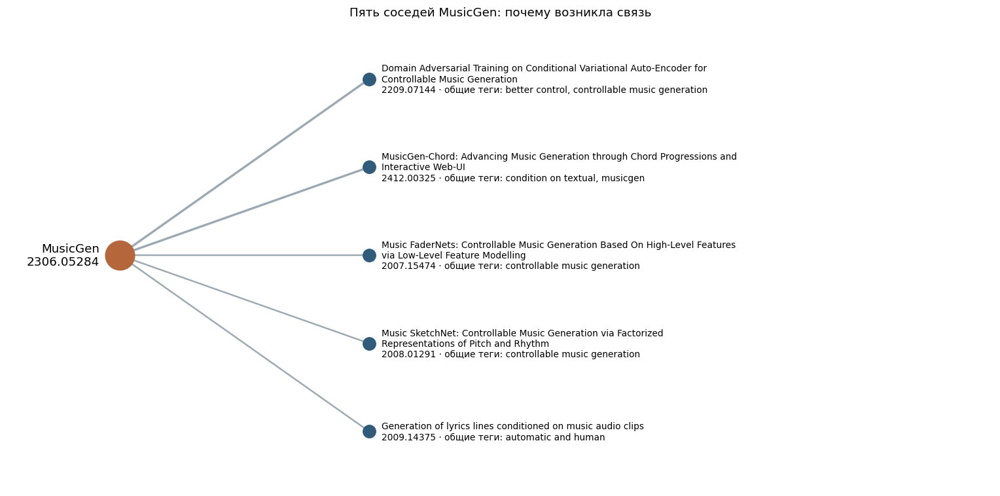

,Минимум общих тегов,Рёбер,Компонент,Изолированных,В крупнейшей компоненте
0,1,13293,1,0,793
1,2,1046,217,177,506
2,3,142,685,636,27
3,4,29,764,738,3


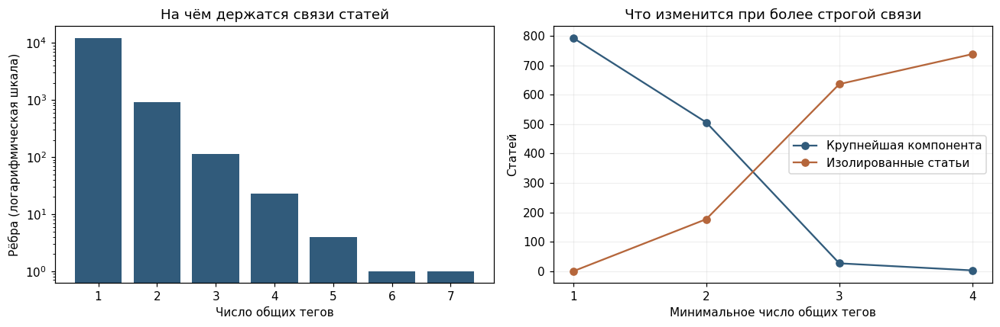

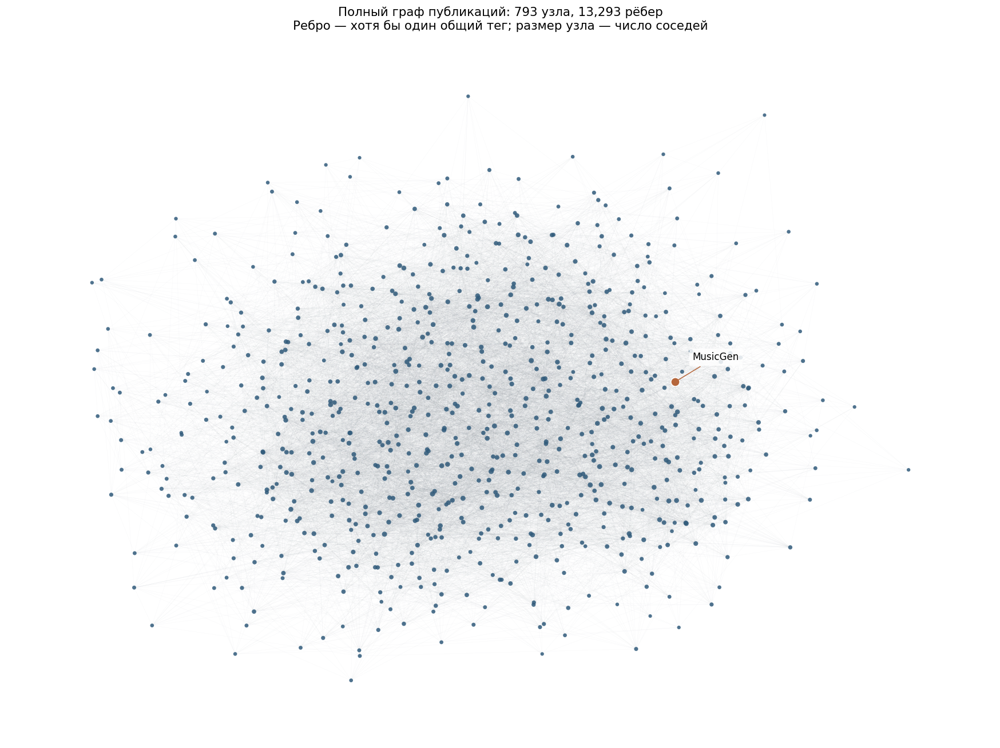

In [26]:
neighbors = recommend(P, papers, keywords_by_id, example_id, top_k=5)
import textwrap
fig, ax = plt.subplots(figsize=(14, 7))
ax.scatter([0], [2], s=850, color='#b5663b', zorder=3)
ax.text(-.08, 2, 'MusicGen\n2306.05284', ha='right', va='center', fontsize=12)
for index, row in enumerate(neighbors.itertuples()):
    y = 4 - index
    ax.plot([0, 1], [2, y], color='#9ba9b2', linewidth=1+row.shared_count*.6, zorder=1)
    ax.scatter([1], [y], s=160, color='#315b7b', zorder=3)
    label = textwrap.fill(row.title, width=75) + '\n' + row.arxiv_id + ' · общие теги: ' + row.shared_keywords
    ax.text(1.05, y, label, va='center', fontsize=9)
ax.set(xlim=(-.45, 3.5), ylim=(-.65, 4.65), title='Пять соседей MusicGen: почему возникла связь')
ax.axis('off')
fig.tight_layout(); save_figure('05_publication_neighborhood')

edge_counts = Counter(attrs['weight'] for _, _, attrs in P.edges(data=True))
threshold_rows = []
for threshold in (1, 2, 3, 4):
    filtered = P.copy()
    filtered.remove_edges_from([(left, right) for left, right, attrs in P.edges(data=True)
                                if attrs['weight'] < threshold])
    threshold_rows.append({'Минимум общих тегов': threshold, 'Рёбер': filtered.number_of_edges(),
                           'Компонент': nx.number_connected_components(filtered),
                           'Изолированных': nx.number_of_isolates(filtered),
                           'В крупнейшей компоненте': len(max(nx.connected_components(filtered), key=len))})
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)
threshold_table.to_csv(RESULTS / 'edge_thresholds.csv', index=False, encoding='utf-8-sig')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
weights = sorted(edge_counts)
axes[0].bar([str(weight) for weight in weights], [edge_counts[weight] for weight in weights], color='#315b7b')
axes[0].set(xlabel='Число общих тегов', ylabel='Рёбра (логарифмическая шкала)',
            title='На чём держатся связи статей', yscale='log')
axes[1].plot(threshold_table['Минимум общих тегов'], threshold_table['В крупнейшей компоненте'],
             'o-', color='#315b7b', label='Крупнейшая компонента')
axes[1].plot(threshold_table['Минимум общих тегов'], threshold_table['Изолированных'],
             'o-', color='#b5663b', label='Изолированные статьи')
axes[1].set(xlabel='Минимальное число общих тегов', ylabel='Статей',
            title='Что изменится при более строгой связи', xticks=[1, 2, 3, 4])
axes[1].legend(); axes[1].grid(alpha=0.2)
fig.tight_layout(); save_figure('06_edge_thresholds')

full_paper_pos = nx.spring_layout(P, seed=SEED, weight='weight', iterations=65, method='force')
fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_edges(P, full_paper_pos, ax=ax, alpha=0.045, width=0.3, edge_color='#52606d')
nx.draw_networkx_nodes(P, full_paper_pos, ax=ax, node_color='#315b7b',
                       node_size=[8 + 3 * np.sqrt(P.degree(node)) for node in P],
                       linewidths=0, alpha=0.85)
nx.draw_networkx_nodes(P, full_paper_pos, ax=ax, nodelist=[example_id],
                       node_color='#b5663b', node_size=100, edgecolors='white', linewidths=1)
ax.annotate('MusicGen', xy=full_paper_pos[example_id], xytext=(20, 25),
            textcoords='offset points', fontsize=11,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85),
            arrowprops=dict(arrowstyle='-', color='#b5663b'))
ax.set_title(f'Полный граф публикаций: {P.number_of_nodes():,} узла, {P.number_of_edges():,} рёбер'
             '\nРебро — хотя бы один общий тег; размер узла — число соседей', fontsize=14)
ax.axis('off')
fig.tight_layout()
save_figure('05_full_publication_graph')


## 6 Текстовый поиск

У Domain Adversarial VAE и MusicGen-Chord по два общих тега с MusicGen, хотя совпадения `musicgen` и `condition on textual` конкретнее общих фраз о контроле.

92,1% рёбер основаны на одном теге. Порог ≥2 оставляет 1 046 рёбер и 177 изолированных статей; основной порог ≥1.

TF-IDF-сходства задают персонализацию PageRank, $\alpha=0{,}85$. Балл:

$$s_d=\cos(q,d)\left(0{,}5+0{,}5\frac{PR_d}{\max_j PR_j}\right).$$

Поиск использует полный словарь TF-IDF. Нулевые текстовые совпадения исключаются.


In [27]:
queries = ['text to music diffusion', 'symbolic piano generation', 'video background music generation', 'separate instrument stems music generation', 'long form symbolic music structure', 'audio prompt drum rhythm generation']
search_examples = {}
for query in queries:
    display(Markdown('### ' + query))
    result = graph_search(P, papers, vectorizer, matrix, query, top_k=5)
    search_examples[query] = result.to_dict('records')
    display(result[['arxiv_id', 'title', 'lexical', 'score', 'url']].round(5))
    lexical = (matrix @ vectorizer.transform([query]).T).toarray().ravel()
    baseline = papers[['arxiv_id', 'title']].assign(cosine=lexical)
    baseline = baseline[baseline.cosine > 0].sort_values(['cosine', 'arxiv_id'], ascending=[False, True]).head(5)
    display(Markdown('TF-IDF без графа:'))
    display(baseline)
(RESULTS / 'search_examples.json').write_text(json.dumps(search_examples, ensure_ascii=False, indent=2), encoding='utf-8')

### text to music diffusion

,arxiv_id,title,lexical,score,url
0,2402.06178,MusicMagus: Zero-Shot Text-to-Music Editing via Diffusion Models,0.24292,0.24292,https://arxiv.org/abs/2402.06178
1,2309.11140,Investigating Personalization Methods in Text to Music Generation,0.23556,0.20969,https://arxiv.org/abs/2309.11140
2,2403.11706,Generalized Multi-Source Inference for Text Conditioned Music Diffusion Models,0.21133,0.18520,https://arxiv.org/abs/2403.11706
3,2605.22717,Live Music Diffusion Models: Efficient Fine-Tuning and Post-Training of Interacti...,0.19276,0.15642,https://arxiv.org/abs/2605.22717
4,2602.01645,Membership Inference Attack Against Music Diffusion Models via Generative Manifol...,0.19100,0.15264,https://arxiv.org/abs/2602.01645


TF-IDF без графа:

,arxiv_id,title,cosine
319,2402.06178,MusicMagus: Zero-Shot Text-to-Music Editing via Diffusion Models,0.242921
272,2309.11140,Investigating Personalization Methods in Text to Music Generation,0.235565
333,2403.11706,Generalized Multi-Source Inference for Text Conditioned Music Diffusion Models,0.211331
708,2605.22717,Live Music Diffusion Models: Efficient Fine-Tuning and Post-Training of Interacti...,0.192761
654,2602.01645,Membership Inference Attack Against Music Diffusion Models via Generative Manifol...,0.191002


### symbolic piano generation

...

### audio prompt drum rhythm generation

,arxiv_id,title,lexical,score,url
0,2509.15625,The Rhythm In Anything: Audio-Prompted Drums Generation with Masked Language Mode...,0.33185,0.33185,https://arxiv.org/abs/2509.15625
1,2509.05145,Exploring Situated Stabilities of a Rhythm Generation System through Variational ...,0.26986,0.21821,https://arxiv.org/abs/2509.05145
2,2601.02357,DARC: Drum accompaniment generation with fine-grained rhythm control,0.17378,0.14637,https://arxiv.org/abs/2601.02357
3,2209.10016,Setting the rhythm scene: deep learning-based drum loop generation from arbitrary...,0.17843,0.13298,https://arxiv.org/abs/2209.10016
4,2405.07034,Towards an Accessible and Rapidly Trainable Rhythm Sequencer Using a Generative S...,0.14203,0.10469,https://arxiv.org/abs/2405.07034


TF-IDF без графа:

,arxiv_id,title,cosine
586,2509.15625,The Rhythm In Anything: Audio-Prompted Drums Generation with Masked Language Mode...,0.331854
575,2509.05145,Exploring Situated Stabilities of a Rhythm Generation System through Variational ...,0.269862
177,2209.10016,Setting the rhythm scene: deep learning-based drum loop generation from arbitrary...,0.178427
645,2601.02357,DARC: Drum accompaniment generation with fine-grained rhythm control,0.173781
343,2405.07034,Towards an Accessible and Rapidly Trainable Rhythm Sequencer Using a Generative S...,0.142026


9432

## 7 Проверка поиска

Структурные тесты проверяют веса всех 314 028 пар статей, петли, Жаккар, порядок выдачи и пограничные случаи.

Слабые метки по словам переоценивают качество, поэтому сохранена разметка выдачи по аннотациям. В парном сравнении TF-IDF и поиска с графом состав top-5 совпал: 30 уникальных пар «запрос–статья». Число попаданий по шести запросам: 4, 5, 4, 3, 1, 2. Средняя Precision@5=0,633; nDCG@5: 0,9180 у TF-IDF и 0,8979 с графом. Идеальный порядок учитывает только известные положительные метки внутри объединения top-5.

Ошибка MIDI-SAG: MIDI используется на входе, результатом служит аудио, а запрос требует нотный выход.

### Сравнение с BM25

Тот же словарь 1–3-грамм и удвоенный заголовок; длина документа считается в нормализованных словах. `k1=1.2`, `b=0.75` заданы без подбора по тесту. Общий пул top-5 трёх методов содержит 34 пары «запрос–статья»; четыре новые оценки сохранены с цитатами из аннотаций. nDCG всех методов пересчитан по этому пулу. Независимой разметки нет, шести запросов недостаточно для вывода об устойчивом преимуществе.

### Фильтры по ролям

Для 18 статей вручную размечены вход, выход, задача и условия с цитатами из аннотаций. На одном подграфе фильтр применяется после ранжирования: AND между полями, OR внутри поля. Неизвестные свойства исключаются, ответов может быть меньше пяти. Роли задаются явно.

В парных сценариях меняются только ограничения. Подборка составлена по уже найденным ошибкам, второго оценщика нет; это демонстрация фильтра, без независимой оценки качества и полноты.


In [28]:
toy = pd.DataFrame({'arxiv_id': ['A', 'B', 'C', 'D'], 'title': ['a', 'b', 'c', 'd'],
                    'year': [2020]*4, 'url': ['https://example.org/'+x for x in 'ABCD']})
toy_tags = [['piano', 'melody', 'transformer'], ['piano', 'melody'], ['piano'], ['isolated']]
toy_graph = publication_graph(toy, toy_tags)
toy_mapping = dict(zip(toy.arxiv_id, toy_tags))
assert toy_graph['A']['B']['weight'] == 2
assert toy_graph['A']['C']['weight'] == 1
assert recommend(toy_graph, toy, toy_mapping, 'A', 2).arxiv_id.tolist() == ['B', 'C']
assert recommend(toy_graph, toy, toy_mapping, 'D').empty
try:
    recommend(toy_graph, toy, toy_mapping, 'unknown')
    raise AssertionError('Ожидалась ошибка неизвестного ID')
except ValueError:
    pass
assert nx.number_of_selfloops(P) == 0
for left, right in combinations(papers.arxiv_id, 2):
    common = len(set(keywords_by_id[left]) & set(keywords_by_id[right]))
    assert P.has_edge(left, right) == (common > 0)
    if common:
        assert P[left][right]['weight'] == common
for article_id in papers.arxiv_id:
    result = recommend(P, papers, keywords_by_id, article_id, 5)
    assert article_id not in set(result.arxiv_id)
    assert result.arxiv_id.is_unique
    assert result.shared_count.is_monotonic_decreasing
assert resolve_publication(papers, example_id) == example_id
assert graph_search(P, papers, vectorizer, matrix, 'zzzznonexistentzzzz').empty
assert graph_search(P, papers, vectorizer, matrix, '   ').empty
print('PASS: известные веса и порядок на контрольном графе, все реальные рёбра, отсутствие петель,')
print('выдача для каждой статьи, неизвестный ID, изолированный узел и запрос без совпадений.')
assert normalized_words('GANs MIDI LLMs VAEs has models') == ['gan', 'midi', 'llm', 'vae', 'have', 'model']
assert 'text to music' in keyword_candidates('text-to-music')
assert 'piano melody' not in keyword_candidates('piano. melody')
assert 'piano melody' not in keyword_candidates('piano and melody')
assert 'piano and melody' in keyword_candidates('piano and melody')
expected_terms = Counter(term for terms in keyword_sets for term in set(terms))
expected_edges = Counter(pair for terms in keyword_sets for pair in combinations(sorted(set(terms)), 2))
assert set(G) == set(expected_terms)
assert G.number_of_edges() == len(expected_edges)
for term, count in expected_terms.items():
    assert G.nodes[term]['document_frequency'] == count
for (left, right), weight in expected_edges.items():
    assert G[left][right]['weight'] == weight
    assert np.isclose(G[left][right]['distance'], 1 / weight)
for article_id in papers.arxiv_id:
    source_terms = set(keywords_by_id[article_id])
    expected = sorted(P.neighbors(article_id), key=lambda other: (
        -P[article_id][other]['weight'],
        -len(source_terms & set(keywords_by_id[other])) / len(source_terms | set(keywords_by_id[other])), other))[:5]
    result = recommend(P, papers, keywords_by_id, article_id, 5)
    assert result.arxiv_id.tolist() == expected
    for row in result.itertuples():
        common = source_terms & set(keywords_by_id[row.arxiv_id])
        assert row.shared_keywords == ', '.join(sorted(common))
        assert np.isclose(row.jaccard, len(common) / len(source_terms | set(keywords_by_id[row.arxiv_id])))
for function in (lambda: resolve_publication(papers, ''),
                 lambda: resolve_publication(papers, 'Music'),
                 lambda: graph_search(P, papers, vectorizer, matrix, 'piano', top_k=0)):
    try:
        function()
        raise AssertionError('Ожидалась ошибка некорректного ввода')
    except ValueError:
        pass
for query in queries:
    result = graph_search(P, papers, vectorizer, matrix, query, top_k=5)
    assert result.arxiv_id.is_unique and result.score.is_monotonic_decreasing
    assert np.isfinite(result[['lexical', 'pagerank', 'score']]).all().all()
    assert result.lexical.gt(0).all()
print('PASS: исходные Atom XML, нормализация, веса графа терминов, Жаккар и порядок всех рекомендаций.')

PASS: известные веса и порядок на контрольном графе, все реальные рёбра, отсутствие петель,
выдача для каждой статьи, неизвестный ID, изолированный узел и запрос без совпадений.
PASS: исходные Atom XML, нормализация, веса графа терминов, Жаккар и порядок всех рекомендаций.


In [29]:
raw_text = (papers.title + ' ' + papers.abstract).str.lower()
weak_masks = [raw_text.str.contains('diffusion') & raw_text.str.contains('music'),
              raw_text.str.contains('piano') & raw_text.str.contains(r'generat|compos', regex=True),
              raw_text.str.contains('video') & raw_text.str.contains('music') & raw_text.str.contains('generat'),
              raw_text.str.contains(r'\bstems?\b|source separation', regex=True) & raw_text.str.contains('music'),
              raw_text.str.contains(r'long.form|long.term|long.duration|long.range|musical structure', regex=True) & raw_text.str.contains(r'symbolic|midi', regex=True),
              raw_text.str.contains('drum') & raw_text.str.contains(r'rhythm|audio.prompt|beatbox', regex=True)]

evaluation = []
for query, mask in zip(queries, weak_masks):
    relevant_ids = set(papers.loc[mask, 'arxiv_id'])
    assert relevant_ids, 'Нет положительных слабых меток для запроса'
    graph_ids = graph_search(P, papers, vectorizer, matrix, query, top_k=5).arxiv_id.tolist()
    cosine = (matrix @ vectorizer.transform([query]).T).toarray().ravel()
    baseline_ids = papers.assign(cosine=cosine).sort_values(['cosine', 'arxiv_id'], ascending=[False, True]).head(5).arxiv_id.tolist()
    for method, found in [('TF-IDF', baseline_ids), ('TF-IDF + graph', graph_ids)]:
        labels = np.array([int(article_id in relevant_ids) for article_id in found])
        dcg = np.sum(labels / np.log2(np.arange(len(labels)) + 2))
        ideal = np.sum(1 / np.log2(np.arange(min(5, len(relevant_ids))) + 2))
        evaluation.append({'Запрос': query, 'Метод': method, 'Слабых релевантных': len(relevant_ids),
                           'Precision@5': labels.sum()/5, 'nDCG@5': dcg/ideal})
evaluation = pd.DataFrame(evaluation)
display(evaluation.round(4))
evaluation.to_csv(RESULTS / 'search_evaluation.csv', index=False, encoding='utf-8-sig')

,Запрос,Метод,Слабых релевантных,Precision@5,nDCG@5
0,text to music diffusion,TF-IDF,147,1.0,1.0000
1,text to music diffusion,TF-IDF + graph,147,1.0,1.0000
2,symbolic piano generation,TF-IDF,78,1.0,1.0000
3,symbolic piano generation,TF-IDF + graph,78,1.0,1.0000
4,video background music generation,TF-IDF,72,1.0,1.0000
5,video background music generation,TF-IDF + graph,72,1.0,1.0000
6,separate instrument stems music generation,TF-IDF,34,1.0,1.0000
7,separate instrument stems music generation,TF-IDF + graph,34,1.0,1.0000
8,long form symbolic music structure,TF-IDF,31,0.4,0.3601
9,long form symbolic music structure,TF-IDF + graph,31,0.4,0.3156


Прямых попаданий  \
query                                      method                             
audio prompt drum rhythm generation        TF-IDF                         2   
                                           TF-IDF + graph                 2   
long form symbolic music structure         TF-IDF                         1   
                                           TF-IDF + graph                 1   
separate instrument stems music generation TF-IDF                         3   
                                           TF-IDF + graph                 3   
symbolic piano generation                  TF-IDF                         5   
                                           TF-IDF + graph                 5   
text to music diffusion                    TF-IDF                         4   
                                           TF-IDF + graph                 4   
video background music generation          TF-IDF                         4   
                                           TF-IDF + graph                 4   

                                                           Просмотрено  \
query                                      method                        
audio prompt drum rhythm generation        TF-IDF                    5   
                                           TF-IDF + graph            5   
long form symbolic music structure         TF-IDF                    5   
                                           TF-IDF + graph            5   
separate instrument stems music generation TF-IDF                    5   
                                           TF-IDF + graph            5   
symbolic piano generation                  TF-IDF                    5   
                                           TF-IDF + graph            5   
text to music diffusion                    TF-IDF                    5   
                                           TF-IDF + graph            5   
video background music generation          TF-IDF                    5   
                                           TF-IDF + graph            5   

                                                           Precision@5  
query                                      method                       
audio prompt drum rhythm generation        TF-IDF                  0.4  
                                           TF-IDF + graph          0.4  
long form symbolic music structure         TF-IDF                  0.2  
                                           TF-IDF + graph          0.2  
separate instrument stems music generation TF-IDF                  0.6  
                                           TF-IDF + graph          0.6  
symbolic piano generation                  TF-IDF                  1.0  
                                           TF-IDF + graph          1.0  
text to music diffusion                    TF-IDF                  0.8  
                                           TF-IDF + graph          0.8  
video background music generation          TF-IDF                  0.8  
                                           TF-IDF + graph          0.8

Ошибки, заметные после чтения аннотаций:

,query,arxiv_id,title,reason,url
4,text to music diffusion,2602.01645,Membership Inference Attack Against Music Diffusion Models via Generative Manifol...,Атакует модель для определения принадлежности записи обучающему набору; это аудит...,https://arxiv.org/abs/2602.01645
14,video background music generation,2507.05894,MusiScene: Leveraging MU-LLaMA for Scene Imagination and Enhanced Video Backgroun...,MusiScene создаёт описания воображаемых сцен; они помогают последующему генератор...,https://arxiv.org/abs/2507.05894
18,separate instrument stems music generation,2607.26874,Detection of AI-generated stems within hybrid human-AI music,Определяет наличие синтетической дорожки в готовом миксе; не генерирует редактиру...,https://arxiv.org/abs/2607.26874
19,separate instrument stems music generation,2103.14208,Modeling the Compatibility of Stem Tracks to Generate Music Mashups,Оценивает совместимость уже выделенных дорожек для mashup; это не генератор или р...,https://arxiv.org/abs/2103.14208
20,long form symbolic music structure,2404.10301,Long-form music generation with latent diffusion,"Создаёт длинное готовое аудио, а запрос требует символьный выход.",https://arxiv.org/abs/2404.10301
22,long form symbolic music structure,2603.21073,SqueezeComposer: Temporal Speed-up is A Simple Trick for Long-form Music Composing,Генерирует и замедляет аудио в ускоренном временном масштабе; символьный выход не...,https://arxiv.org/abs/2603.21073
23,long form symbolic music structure,2602.22029,MIDI-Informed Singing Accompaniment Generation in a Compositional Song Pipeline,MIDI используется как управляющий вход для звучащего аккомпанемента; это не генер...,https://arxiv.org/abs/2602.22029
24,long form symbolic music structure,2601.03973,Muse: Towards Reproducible Long-Form Song Generation with Fine-Grained Style Control,Генерирует длинные песни по аудиотокенам; выход не является MIDI или нотами.,https://arxiv.org/abs/2601.03973
26,audio prompt drum rhythm generation,2509.05145,Exploring Situated Stabilities of a Rhythm Generation System through Variational ...,Разбирает художественные применения ритм-системы; требуемое управление ритмом чер...,https://arxiv.org/abs/2509.05145
27,audio prompt drum rhythm generation,2209.10016,Setting the rhythm scene: deep learning-based drum loop generation from arbitrary...,"Барабанный паттерн задаётся английским словом или фразой, а запрос требует аудиоп...",https://arxiv.org/abs/2209.10016


,Среднее по шести запросам
method,
TF-IDF,0.633333
TF-IDF + graph,0.633333


,Запрос,Метод,Precision@5,nDCG@5 по пулу
0,audio prompt drum rhythm generation,TF-IDF,0.4,0.8772
1,audio prompt drum rhythm generation,TF-IDF + graph,0.4,0.9197
2,long form symbolic music structure,TF-IDF,0.2,0.6309
3,long form symbolic music structure,TF-IDF + graph,0.2,0.5000
4,separate instrument stems music generation,TF-IDF,0.6,1.0000
5,separate instrument stems music generation,TF-IDF + graph,0.6,0.9675
6,symbolic piano generation,TF-IDF,1.0,1.0000
7,symbolic piano generation,TF-IDF + graph,1.0,1.0000
8,text to music diffusion,TF-IDF,0.8,1.0000
9,text to music diffusion,TF-IDF + graph,0.8,1.0000


,Precision@5,nDCG@5 по пулу
Метод,,
TF-IDF,0.6333,0.9180
TF-IDF + graph,0.6333,0.8979


,Запрос,Метод,Precision@5,RR@5,nDCG@5 по общему пулу
0,audio prompt drum rhythm generation,BM25,0.4,1.000,0.877
1,audio prompt drum rhythm generation,TF-IDF,0.4,1.000,0.877
2,audio prompt drum rhythm generation,TF-IDF + graph,0.4,1.000,0.920
3,long form symbolic music structure,BM25,0.2,0.200,0.387
4,long form symbolic music structure,TF-IDF,0.2,0.500,0.631
5,long form symbolic music structure,TF-IDF + graph,0.2,0.333,0.500
6,separate instrument stems music generation,BM25,0.6,1.000,0.805
7,separate instrument stems music generation,TF-IDF,0.6,1.000,0.832
8,separate instrument stems music generation,TF-IDF + graph,0.6,1.000,0.805
9,symbolic piano generation,BM25,1.0,1.000,1.000


,Precision@5,MRR@5,nDCG@5 по общему пулу
Метод,,,
BM25,0.667,0.867,0.845
TF-IDF,0.633,0.917,0.868
TF-IDF + graph,0.633,0.889,0.849


,query,title,directly_relevant,reason
0,text to music diffusion,DITTO: Diffusion Inference-Time T-Optimization for Music Generation,1,Управляет предобученной text-to-music diffusion моделью на этапе генерации; управ...
1,symbolic piano generation,Expressive MIDI-format Piano Performance Generation,1,Нейросеть генерирует выразительное фортепианное исполнение в MIDI; символьный вых...
2,separate instrument stems music generation,DTT-BSR+: A Generative-Regression Cascade for Music Source Restoration,1,Генеративный разделитель создаёт очищенные дорожки источников; разделение допуска...
3,audio prompt drum rhythm generation,Towards democratizing music production with AI-Design of Variational Autoencoder-...,0,Обучает генератор ритма на выбранных MIDI-файлах. Управление генерацией через ауд...


Предварительная оценка по аннотациям: 6 запросов, 34 пары запрос–статья; независимой разметки нет.
nDCG пересчитан для всех методов по общему пулу. Его нельзя напрямую сравнивать с прежним меньшим пулом.


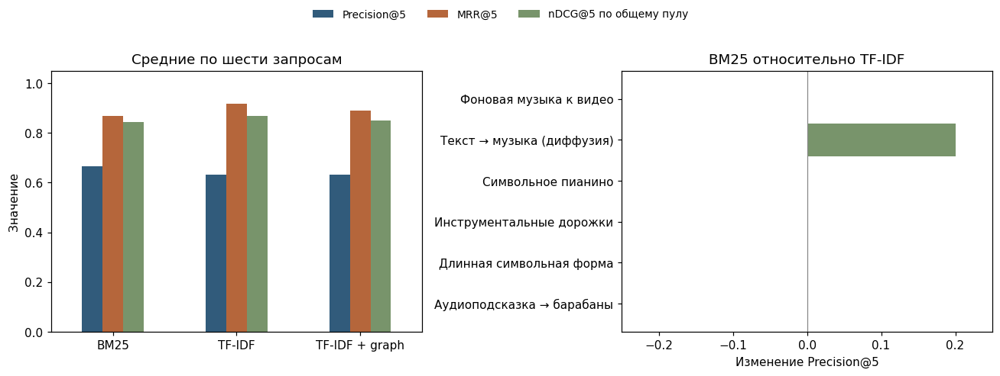

**Текст → ноты** · text conditioned music generation

,title,inputs,outputs,tasks,Основание
1,MuseCoco: Generating Symbolic Music from Text,text,symbolic,generation,MuseCoco: текстовые описания задают символьную музыку.
3,Diff-Symbo: Text-Controlled Long-Duration Symbolic Music Generation Using Autoreg...,text,symbolic,generation,Diff-Symbo: текстовое управление длинной символьной музыкой.


**Текст → аудио** · text conditioned music generation

,title,inputs,outputs,tasks,Основание
0,Generalized Multi-Source Inference for Text Conditioned Music Diffusion Models,"text, audio","stems, audio","generation, separation","Генерация источников и аккомпанемента, также разделение."
2,Mustango: Toward Controllable Text-to-Music Generation,text,audio,generation,Mustango: текст задаёт музыкальные условия.
7,Simple and Controllable Music Generation,"text, melody",audio,generation,MusicGen: аудио по текстовому описанию или мелодии.
10,Long-form music generation with latent diffusion,text,audio,generation,Длинная аудиомузыка по тексту; символьный выход не заявлен.


**Аудиоподсказка → барабаны** · prompt drum rhythm generation

...

,title,inputs,outputs,tasks,Основание
3,Melody Structure Transfer Network: Generating Music with Separable Self-Attention,symbolic,symbolic,generation,"Перенос структуры символьной музыки, до 100 тактов."
4,Diff-Symbo: Text-Controlled Long-Duration Symbolic Music Generation Using Autoreg...,text,symbolic,generation,Diff-Symbo: текстовое управление длинной символьной музыкой.


**Создать или выделить дорожки** · separate instrument stems music generation

,title,inputs,outputs,tasks,Основание
0,Separate-and-Detect: Unified Drum Transcription and Stem Generation via Latent Di...,audio,"stems, audio, symbolic, drums","separation, transcription",Из смеси получаются дорожки и события; это разделение и транскрипция.
2,DARC: Drum accompaniment generation with fine-grained rhythm control,"audio, audio_prompt","audio, drums, stems",generation,DARC: контекст дорожек и ритмическая аудиоподсказка.
3,User-guided Generative Source Separation,"audio, audio_prompt","stems, audio",separation,"GuideSep: выделение источника из микса, подсказка может быть напета."
4,Generalized Multi-Source Inference for Text Conditioned Music Diffusion Models,"text, audio","stems, audio","generation, separation","Генерация источников и аккомпанемента, также разделение."


,Сценарий,До фильтра,После фильтра,Выдано после фильтра
0,Текст → ноты,"2403.11706, 2306.00110, 2311.08355, 2608.05222, 2402.06178","2306.00110, 2608.05222",2
1,Текст → аудио,"2403.11706, 2306.00110, 2311.08355, 2608.05222, 2402.06178","2403.11706, 2311.08355, 2306.05284, 2404.10301",4
2,Аудиоподсказка → барабаны,"2601.02357, 2509.15625, 2209.10016, 2608.01093, 2507.01339","2601.02357, 2509.15625",2
3,Текст → барабаны,"2601.02357, 2509.15625, 2209.10016, 2608.01093, 2507.01339",2209.10016,1
4,Длинная нотная форма,"2404.10301, 2503.08638, 2602.22029, 2107.09877, 2608.05222","2107.09877, 2608.05222",2
5,Создать или выделить дорожки,"2608.01093, 2607.26874, 2601.02357, 2507.01339, 2403.11706","2608.01093, 2601.02357, 2507.01339, 2403.11706",4


PASS: 18 оснований найдены в аннотациях; фильтры шести сценариев и пограничные случаи проверены.


In [30]:
review_candidates = []
for query in queries:
    found = graph_search(P, papers, vectorizer, matrix, query, top_k=5)
    cosine = (matrix @ vectorizer.transform([query]).T).toarray().ravel()
    baseline = papers.assign(cosine=cosine).sort_values(['cosine', 'arxiv_id'], ascending=[False, True]).head(5)
    for method, ranking in [('TF-IDF', baseline), ('TF-IDF + graph', found)]:
        for rank, row in enumerate(ranking.itertuples(), 1):
            record = papers.set_index('arxiv_id').loc[row.arxiv_id]
            review_candidates.append({'query': query, 'method': method, 'rank': rank,
                                      'arxiv_id': row.arxiv_id, 'title': row.title,
                                      'abstract': record.abstract, 'url': record.url})
(RESULTS / 'review_candidates.json').write_text(json.dumps(review_candidates, ensure_ascii=False, indent=2), encoding='utf-8')
manual_review = pd.read_csv(RESULTS / 'search_manual_review.csv', dtype={'arxiv_id': str})
rankings = pd.DataFrame(review_candidates)
assert not manual_review.duplicated(['query', 'arxiv_id']).any()
assert set(map(tuple, manual_review[['query','arxiv_id']].to_numpy())) == set(map(tuple, rankings[['query','arxiv_id']].to_numpy()))
assert manual_review.directly_relevant.isin([0,1]).all()
judged_rankings = rankings.merge(manual_review[['query','arxiv_id','directly_relevant','reason']],
                                on=['query','arxiv_id'], how='left', validate='many_to_one')
manual_quality = judged_rankings.groupby(['query','method']).directly_relevant.agg(['sum','count'])
assert manual_quality['count'].eq(5).all()
manual_quality['Precision@5'] = manual_quality['sum'] / manual_quality['count']
display(manual_quality.rename(columns={'sum':'Прямых попаданий','count':'Просмотрено'}))
display(Markdown('Ошибки, заметные после чтения аннотаций:'))
display(manual_review[manual_review.directly_relevant.eq(0)][['query','arxiv_id','title','reason','url']])
manual_quality.to_csv(RESULTS / 'search_manual_metrics.csv', encoding='utf-8-sig')
display(manual_quality.groupby('method')['Precision@5'].mean().rename('Среднее по шести запросам').to_frame())


# nDCG нормирован по известным положительным меткам в объединении top-5.
# Неразмеченные документы вне пула не считаются отрицательными.
ranking_rows = []
for (query, method), group in judged_rankings.groupby(['query', 'method']):
    rel = group.sort_values('rank').directly_relevant.to_numpy()
    known_relevant = manual_review.loc[manual_review['query'].eq(query), 'directly_relevant'].sum()
    ideal = np.sum(1/np.log2(np.arange(min(5, int(known_relevant)))+2))
    dcg = np.sum(rel/np.log2(np.arange(len(rel))+2))
    ranking_rows.append({'Запрос': query, 'Метод': method,
                         'Precision@5': rel.sum()/5, 'nDCG@5 по пулу': dcg/ideal if ideal else np.nan})
manual_ranking = pd.DataFrame(ranking_rows)
display(manual_ranking.round(4))
display(manual_ranking.groupby('Метод')[['Precision@5', 'nDCG@5 по пулу']].mean().round(4))
manual_ranking.to_csv(RESULTS / 'manual_ranking_metrics.csv', index=False, encoding='utf-8-sig')

# Те же 1–3-граммы и повтор заголовка, что у TF-IDF; параметры заданы до сравнения.
from sklearn.feature_extraction.text import CountVectorizer
bm25_counter = CountVectorizer(analyzer=keyword_candidates, vocabulary=vectorizer.vocabulary_)
bm25_texts = (papers.title + '. ' + papers.title + '. ' + papers.abstract).tolist()
bm25_counts = bm25_counter.fit_transform(bm25_texts).tocsc()
bm25_lengths = np.array([len(normalized_words(text)) for text in bm25_texts])
bm25_df = np.diff(bm25_counts.indptr)
bm25_idf = np.log1p((len(papers) - bm25_df + .5) / (bm25_df + .5))
BM25_K1, BM25_B = 1.2, .75

def bm25_search(query, top_k=5):
    if top_k < 1:
        raise ValueError('top_k должен быть положительным')
    query_terms = bm25_counter.transform([query]).indices
    scores = np.zeros(len(papers))
    length_norm = BM25_K1 * (1 - BM25_B + BM25_B * bm25_lengths / bm25_lengths.mean())
    for term in query_terms:
        start, stop = bm25_counts.indptr[term:term+2]
        rows = bm25_counts.indices[start:stop]
        tf = bm25_counts.data[start:stop]
        scores[rows] += bm25_idf[term] * tf * (BM25_K1 + 1) / (tf + length_norm[rows])
    ranked = papers[['arxiv_id', 'title', 'abstract', 'url']].assign(score=scores)
    return ranked[ranked.score > 0].sort_values(['score', 'arxiv_id'], ascending=[False, True]).head(top_k)

assert bm25_search('zzzznonexistentzzzz').empty
assert bm25_search('   ').empty
for invalid_k in (0, -1):
    try:
        bm25_search('piano', top_k=invalid_k)
        raise AssertionError('Ожидалась ошибка некорректного top_k')
    except ValueError:
        pass
comparison_rows = []
for query in queries:
    cosine = (matrix @ vectorizer.transform([query]).T).toarray().ravel()
    baseline = papers.assign(score=cosine)
    baseline = baseline[baseline.score > 0].sort_values(['score', 'arxiv_id'], ascending=[False, True]).head(5)
    graph_ranked = graph_search(P, papers, vectorizer, matrix, query, top_k=5)
    bm25_ranked = bm25_search(query)
    for method, ranked in [('TF-IDF', baseline), ('TF-IDF + graph', graph_ranked), ('BM25', bm25_ranked)]:
        for rank, row in enumerate(ranked.itertuples(), 1):
            comparison_rows.append({'query': query, 'method': method, 'rank': rank,
                                    'arxiv_id': row.arxiv_id, 'title': row.title, 'score': row.score})
comparison_rankings = pd.DataFrame(comparison_rows)
comparison_rankings.to_csv(RESULTS / 'lecture_search_rankings.csv', index=False, encoding='utf-8-sig')

# Общий пул top-5 трёх методов; дополнительные оценки основаны на аннотациях.
bm25_review = pd.DataFrame(json.loads((DATA / 'bm25_additional_judgments.json').read_text(encoding='utf-8')))
for row in bm25_review.itertuples():
    assert row.evidence in papers.set_index('arxiv_id').loc[row.arxiv_id, 'abstract']
comparison_review = pd.concat([manual_review, bm25_review], ignore_index=True)
assert not comparison_review.duplicated(['query', 'arxiv_id']).any()
assert comparison_review.directly_relevant.isin([0, 1]).all()
assert set(map(tuple, comparison_review[['query', 'arxiv_id']].to_numpy())) == set(
    map(tuple, comparison_rankings[['query', 'arxiv_id']].to_numpy()))
comparison_judged = comparison_rankings.merge(
    comparison_review[['query', 'arxiv_id', 'directly_relevant']],
    on=['query', 'arxiv_id'], how='left', validate='many_to_one',
)
comparison_metrics = []
for (query, method), group in comparison_judged.groupby(['query', 'method']):
    relevance = group.sort_values('rank').directly_relevant.to_numpy()
    assert len(relevance) == 5 and not np.isnan(relevance).any()
    relevant_ranks = np.flatnonzero(relevance) + 1
    known_relevant = int(comparison_review.loc[comparison_review['query'].eq(query), 'directly_relevant'].sum())
    ideal = np.sum(1 / np.log2(np.arange(min(5, known_relevant)) + 2))
    dcg = np.sum(relevance / np.log2(np.arange(5) + 2))
    comparison_metrics.append({'Запрос': query, 'Метод': method, 'Precision@5': relevance.sum() / 5,
                               'RR@5': 1 / relevant_ranks[0] if len(relevant_ranks) else 0,
                               'nDCG@5 по общему пулу': dcg / ideal if ideal else np.nan})
comparison_metrics = pd.DataFrame(comparison_metrics)
display(comparison_metrics.round(3))
comparison_mean = comparison_metrics.groupby('Метод')[
    ['Precision@5', 'RR@5', 'nDCG@5 по общему пулу']].mean().rename(columns={'RR@5': 'MRR@5'})
display(comparison_mean.round(3))
comparison_metrics.to_csv(RESULTS / 'lecture_search_metrics.csv', index=False, encoding='utf-8-sig')
comparison_review.to_csv(RESULTS / 'lecture_search_judgments.csv', index=False, encoding='utf-8-sig')
display(bm25_review[['query', 'title', 'directly_relevant', 'reason']])
print('Предварительная оценка по аннотациям: 6 запросов, 34 пары запрос–статья; независимой разметки нет.')
print('nDCG пересчитан для всех методов по общему пулу. Его нельзя напрямую сравнивать с прежним меньшим пулом.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparison_mean.plot.bar(ax=axes[0], color=['#315b7b', '#b5663b', '#78946b'], rot=0)
axes[0].set(xlabel='', ylabel='Значение', ylim=(0, 1.05), title='Средние по шести запросам')
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
axes[0].get_legend().remove()
fig.legend(legend_handles, legend_labels, loc='upper center', ncol=3, frameon=False, fontsize=9)
paired_precision = comparison_metrics.pivot(index='Запрос', columns='Метод', values='Precision@5')
query_labels = {'text to music diffusion': 'Текст → музыка (диффузия)',
                'symbolic piano generation': 'Символьное пианино',
                'video background music generation': 'Фоновая музыка к видео',
                'separate instrument stems music generation': 'Инструментальные дорожки',
                'long form symbolic music structure': 'Длинная символьная форма',
                'audio prompt drum rhythm generation': 'Аудиоподсказка → барабаны'}
delta = (paired_precision['BM25'] - paired_precision['TF-IDF']).rename(index=query_labels)
axes[1].barh(delta.index, delta, color=['#78946b' if value >= 0 else '#b5663b' for value in delta])
axes[1].axvline(0, color='#888888', linewidth=.8)
axes[1].set(xlabel='Изменение Precision@5', xlim=(-.25, .25), title='BM25 относительно TF-IDF')
fig.tight_layout(rect=(0, 0, 1, .9)); save_figure('07_bm25_comparison')


# Поиск с ролями на учебной подборке, без автоматического извлечения ролей.
role_annotations = json.loads((DATA / 'role_annotations.json').read_text(encoding='utf-8'))
role_by_id = {row['arxiv_id']: row for row in role_annotations}
assert len(role_by_id) == len(role_annotations) == 18
for row in role_annotations:
    paper = papers.set_index('arxiv_id').loc[row['arxiv_id']]
    assert row['evidence'].lower() in paper.abstract.lower(), row['arxiv_id']
    assert row['tasks'] and row['outputs']
role_sample = papers[papers.arxiv_id.isin(role_by_id)].copy()
role_matrix = matrix[papers.arxiv_id.isin(role_by_id).to_numpy()]
role_graph = P.subgraph(role_by_id).copy()

def role_search(query, required=None, top_k=5):
    """Ранжирование на том же подграфе, затем строгий фильтр проверенных ролей.

    Условия внутри поля задаются через OR, между полями через AND.
    Неизвестное свойство не проходит фильтр. Роли не извлекаются из запроса.
    """
    if top_k < 1:
        raise ValueError('top_k должен быть положительным')
    required = required or {}
    if set(required) - {'inputs', 'outputs', 'tasks', 'controls'}:
        raise ValueError('Неизвестное поле роли')
    ranked = graph_search(role_graph, role_sample, vectorizer, role_matrix, query, top_k=len(role_sample))
    keep = ranked.arxiv_id.map(lambda aid: all(set(wanted) & set(role_by_id[aid][field])
                                               for field, wanted in required.items() if wanted))
    result = ranked.loc[keep.astype(bool)].head(top_k).copy()
    for field in ('inputs', 'outputs', 'tasks', 'controls'):
        result[field] = result.arxiv_id.map(lambda aid: ', '.join(role_by_id[aid][field]) or 'не указано')
    result['Основание'] = result.arxiv_id.map(lambda aid: role_by_id[aid]['note'])
    return result

role_scenarios = [
    ('Текст → ноты', 'text conditioned music generation', {'inputs':['text'], 'outputs':['symbolic'], 'tasks':['generation']}),
    ('Текст → аудио', 'text conditioned music generation', {'inputs':['text'], 'outputs':['audio'], 'tasks':['generation']}),
    ('Аудиоподсказка → барабаны', 'prompt drum rhythm generation', {'inputs':['audio_prompt'], 'outputs':['drums'], 'tasks':['generation']}),
    ('Текст → барабаны', 'prompt drum rhythm generation', {'inputs':['text'], 'outputs':['drums'], 'tasks':['generation']}),
    ('Длинная нотная форма', 'long form symbolic music structure', {'outputs':['symbolic'], 'controls':['long_form'], 'tasks':['generation']}),
    ('Создать или выделить дорожки', 'separate instrument stems music generation', {'outputs':['stems'], 'tasks':['generation','separation']}),
]
role_comparison = []
for label, query, required in role_scenarios:
    before = role_search(query)
    after = role_search(query, required)
    display(Markdown('**' + label + '** · ' + query))
    display(after[['title', 'inputs', 'outputs', 'tasks', 'Основание']])
    role_comparison.append({'Сценарий': label, 'До фильтра': ', '.join(before.arxiv_id),
                            'После фильтра': ', '.join(after.arxiv_id), 'Выдано после фильтра': len(after)})
    assert not after.empty
    assert all(all(set(wanted) & set(role_by_id[aid][field]) for field, wanted in required.items())
               for aid in after.arxiv_id)
role_comparison = pd.DataFrame(role_comparison)
display(role_comparison)
role_comparison.to_csv(RESULTS / 'role_search_comparison.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(role_annotations).to_json(RESULTS / 'role_annotations.json', orient='records', force_ascii=False, indent=2)
assert '2602.22029' not in set(role_search('long form symbolic music structure', role_scenarios[4][2]).arxiv_id)
assert '2509.15625' in set(role_search('prompt drum rhythm generation', role_scenarios[2][2]).arxiv_id)
assert '2209.10016' not in set(role_search('prompt drum rhythm generation', role_scenarios[2][2]).arxiv_id)
assert '2607.26874' not in set(role_search('separate instrument stems music generation', role_scenarios[5][2]).arxiv_id)
assert role_search('zzzznonexistentzzzz', {'outputs':['symbolic']}).empty
assert role_search('music', {'outputs':['unavailable_role']}).empty
print('PASS: 18 оснований найдены в аннотациях; фильтры шести сценариев и пограничные случаи проверены.')


In [34]:
import ipywidgets as widgets
article_input = widgets.Text(value=example_id, description='Статья:', layout=widgets.Layout(width='80%'))
article_button = widgets.Button(description='Похожие статьи')
article_output = widgets.Output()
def on_article_click(button):
    with article_output:
        article_output.clear_output()
        try:
            article_id = resolve_publication(papers, article_input.value)
            display(recommend(P, papers, keywords_by_id, article_id, top_k=5))
        except ValueError as error:
            print(error)
article_button.on_click(on_article_click)
query_input = widgets.Text(value=queries[0], description='Запрос:', layout=widgets.Layout(width='80%'))
query_button = widgets.Button(description='Поиск по графу')
query_output = widgets.Output()
def on_query_click(button):
    with query_output:
        query_output.clear_output()
        result = graph_search(P, papers, vectorizer, matrix, query_input.value, top_k=5)
        print('Нет совпадений' if result.empty else '')
        display(result)
query_button.on_click(on_query_click)
display(widgets.VBox([article_input, article_button, article_output, query_input, query_button, query_output]))
role_choice = widgets.Dropdown(options=[(label, i) for i, (label, _, _) in enumerate(role_scenarios)],
                               description='Задача:', layout=widgets.Layout(width='80%'))
role_button = widgets.Button(description='Поиск с ролями')
role_output = widgets.Output()
def on_role_click(button):
    with role_output:
        role_output.clear_output()
        label, query, required = role_scenarios[role_choice.value]
        print('Учебная подборка: 18 статей. Только подтверждённые в разметке свойства.')
        display(role_search(query, required)[['title', 'inputs', 'outputs', 'tasks', 'Основание', 'url']])
role_button.on_click(on_role_click)
display(widgets.VBox([role_choice, role_button, role_output]))


In [35]:
summary = {'articles': len(papers), 'years': [int(papers.year.min()), int(papers.year.max())],
           'tokens': int(sum(counts)), 'vocabulary': len(frequency), 'zipf_alpha': float(alpha),
           'zipf_r2': float(r_squared), 'keyword_nodes': len(G), 'keyword_edges': G.number_of_edges(),
           'keyword_components': len(components), 'communities': len(communities), 'modularity': float(modularity),
           'publication_nodes': len(P), 'publication_edges': P.number_of_edges(),
           'publication_components': len(publication_components), 'isolated_publications': nx.number_of_isolates(P),
           'top_degree': top_degree, 'top_betweenness': top_bridge, 'top_eigenvector': top_eigen,
           'metadata_sources': papers.metadata_source.value_counts().to_dict(), 'structural_tests': 'PASS'}
(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
summary['single_tag_edge_share'] = edge_counts[1] / P.number_of_edges()
summary['threshold_2'] = threshold_rows[1]
summary['manual_precision_at_5'] = [{'query':query,'method':method,'precision':float(value)} for (query,method),value in manual_quality['Precision@5'].items()]

(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame({'Показатель': ['Статей из API', 'Терминов', 'Рёбер терминов', 'Сообществ',
                                   'Модулярность', 'Рёбер публикаций', 'Проверки'],
                      'Результат': [len(papers), len(G), G.number_of_edges(), len(communities),
                                    round(modularity, 4), P.number_of_edges(), 'Пройдены']}))
evidence = []
for group, terms in enumerate(communities):
    examples = papers.assign(overlap=papers.keywords.map(lambda tags: len(set(tags) & terms)))
    examples = examples.sort_values(['overlap', 'arxiv_id'], ascending=[False, True]).head(5)
    evidence.append({'group': group, 'top_terms': sorted(terms, key=lambda t: (-strength[t], t))[:15],
                     'examples': examples[['arxiv_id', 'title', 'abstract', 'keywords', 'overlap']].to_dict('records')})
(RESULTS / 'community_evidence.json').write_text(json.dumps(evidence, ensure_ascii=False, indent=2), encoding='utf-8')
(RESULTS / 'extra_stats.json').write_text(json.dumps({
    'year_counts': papers.year.value_counts().sort_index().to_dict(),
    'abstract_median': float(papers.abstract_words.median()), 'author_median': float(papers.author_count.median()),
    'author_max': int(papers.author_count.max()), 'abstract_mean': float(papers.abstract_words.mean()),
    'candidate_terms': len(vectorizer.vocabulary_), 'selected_per_article': papers.keywords.map(len).value_counts().to_dict(),
    'task_counts': task_counts.to_dict(), 'task_year_percent': by_year.to_dict(),
    'centrality_top': {col: centrality.nlargest(5, col).reset_index().to_dict('records')
                       for col in ['degree', 'betweenness', 'closeness', 'eigenvector']},
    'community_sizes': sizes, 'community_comparison': comparisons,
    'random_modularity_mean': float(np.mean(random_q)), 'random_modularity_std': float(np.std(random_q)),
    'edge_counts': dict(edge_counts),
    'recommendations': recommend(P, papers, keywords_by_id, example_id, 7).to_dict('records'),
    'bridge_community_count': len({community_id[neighbor] for neighbor in G[top_bridge]}),
    'bridge_frequency': G.nodes[top_bridge]['document_frequency'], 'bridge_neighbors': G.degree(top_bridge)
}, ensure_ascii=False, indent=2), encoding='utf-8')

(RESULTS / 'betweenness_stability.json').write_text(json.dumps({'sources': 512, 'comparison_sources': 256, 'rank_spearman': float(bc_spearman), 'top_10_overlap': bc_top_overlap}), encoding='utf-8')

summary['cluster_stability'] = cluster_stability.to_dict('records')
summary['single_selection_tag_share'] = singleton_count / len(selected_df)
summary['degree_frequency_spearman'] = float(degree_frequency_spearman)
summary['manual_ndcg_judged_pool'] = manual_ranking.groupby('Метод')['nDCG@5 по пулу'].mean().to_dict()
summary['role_experiment'] = {'articles': len(role_sample), 'scenarios': len(role_scenarios),
                              'scope': 'curated demonstration with checked metadata, not independent evaluation'}
(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

summary['heaps'] = heaps_result
summary['lecture_search_comparison'] = comparison_mean.reset_index().to_dict('records')
summary['lecture_search_evaluation'] = {'queries': len(queries), 'judged_pairs': len(comparison_review),
                                        'scope': 'pooled top-5; preliminary abstract judgments; not independent'}
(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

summary['data_quality_audit'] = {'duplicate_text_groups': duplicate_audit.to_dict('records'),
                               'iqr_outliers': outlier_summary.to_dict('records')}
(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')


,Показатель,Результат
0,Статей из API,793
1,Терминов,3360
2,Рёбер терминов,34628
3,Сообществ,24
4,Модулярность,0.4223
5,Рёбер публикаций,13293
6,Проверки,Пройдены


5140